# RM3100 — Ganancia y sensibilidad con dos series de *cycle count*, y efecto del campo usado ($\hat B$ ajustado frente a IGRF-14)

**Objetivo.** Repetir el análisis de `analisis_sensibilidad.ipynb` con el archivo del 13 de noviembre de 2026, que contiene **dos series** (barridos) consecutivas de 14 valores de *cycle count* (25 a 350 en pasos de 25, 100 muestras cada uno), y comparar:

1. la sensibilidad y la ganancia de cada serie y del **promedio de las dos series** con el datasheet (secciones 6 y 7, como en el notebook original);
2. el resultado que se obtiene al cambiar el campo magnético con el que se convierten las cuentas a ganancia: el campo $\hat B$ ajustado con el modelo del datasheet frente al campo del modelo **IGRF-14** (secciones 8 y 9).

**Definiciones.** Las del datasheet:

- **Ganancia** $G$: cuentas por unidad de campo, en LSB/µT.
- **Sensibilidad** $S$: campo que corresponde a una cuenta, $S=1/G$, en nT/LSB.

**Procedimiento.**

1. Módulo $M$ (LSB) de cada muestra y estadística tipo A por *cycle count*, para cada serie (secciones 1 a 3).
2. Promedio de las dos series y comprobación de que son compatibles entre sí (sección 4).
3. Ganancia y sensibilidad con $\hat B$ ajustado, y recta de mínimos cuadrados, para la serie 1, la serie 2 y el promedio (secciones 5 a 7).
4. Campo del modelo IGRF-14 en el lugar y la fecha de la medición (sección 8).
5. Ganancia y sensibilidad con $\hat B$ y con $B_{\text{IGRF}}$, en el mismo gráfico, para las dos series y el promedio (sección 9).
6. Comparación con el archivo del 12 de noviembre (sección 10).

**Numeración de las ecuaciones.** Las ecuaciones (1) a (27) conservan el número que tienen en el notebook original; las (12) a (14) pertenecen a una sección que aquí no se repite. Las ecuaciones nuevas son las (8a)–(8d) y las (28) en adelante.

**Solo se usa incertidumbre tipo A**, igual que en el notebook original.

In [1]:
from pathlib import Path
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ---- Archivos (se buscan junto al notebook, en la carpeta superior y en src/) ----
ARCHIVO = "datos_raw_rm3100_20261113_163608.txt"            # dos series de cycle count
ARCHIVO_ANTERIOR = "datos_raw_rm3100_20261112_171025.txt"   # solo para la seccion 10
ARCHIVO_IGRF = "igrf14coeffs.txt"                           # coeficientes IGRF-14 (NOAA/IAGA)
K = 2                # factor de cobertura (2 sigma, ~95 %)

# ---- Lugar de la medicion, para el IGRF.  ES UN SUPUESTO: corrigelo si no corresponde ----
LUGAR = "Santiago de Chile (campus USACH)"
LAT_GEOD = -33.4489      # latitud geodesica (grados, norte positivo)
LON = -70.6828           # longitud (grados, este positivo)
ALT_KM = 0.52            # altura sobre el elipsoide (km)

# ---- Valores del fabricante (verificalos contra tu copia del datasheet) ----
# Ganancia nominal: G = DS_PENDIENTE * CC + DS_OFFSET   [LSB/uT]
DS_PENDIENTE = 0.3671
DS_OFFSET = 1.5

# ---- Estilo de los graficos ----
C_DS, C_FIT = "#eb6834", "#1baf7a"                         # datasheet / recta ajustada
TINTA, TINTA2, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
# color, marcador y desplazamiento horizontal (en cuentas de ciclo) de cada serie
ESTILO = {"Serie 1":  dict(color="#2a78d6", marker="o", dx=-4.0),
          "Serie 2":  dict(color="#8e5bd0", marker="s", dx=+4.0),
          "Promedio": dict(color=TINTA,     marker="D", dx=0.0)}
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO,
    "savefig.facecolor": FONDO, "figure.dpi": 110,
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA2, "axes.titlecolor": TINTA,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8,
    "xtick.color": TINTA2, "ytick.color": TINTA2,
    "legend.frameon": False, "font.size": 10,
})


def buscar(nombre):
    """Devuelve la ruta del archivo, buscandolo en ., .. y src/ (None si no existe)."""
    return next((p for p in (Path(nombre), Path("..") / nombre, Path("src") / nombre)
                 if p.exists()), None)


def puntos(ax, x, y, yerr, serie, etiqueta, hueco=False, desplazar=True):
    """Puntos con barra de error (2 sigma) con el estilo de la serie."""
    e = ESTILO[serie]
    ax.errorbar(x + (e["dx"] if desplazar else 0.0), y, yerr=yerr, fmt=e["marker"], ms=5.5,
                color=e["color"], ecolor=e["color"], elinewidth=1.1, capsize=2.5,
                mfc=FONDO if hueco else e["color"], mec=e["color"] if hueco else FONDO,
                mew=1.3 if hueco else 0.8, label=etiqueta, zorder=3)


ruta = buscar(ARCHIVO)
print("Archivo:", ruta.resolve())

Archivo: C:\Users\Yerko J\Desktop\firmware\RM3100-ESP32\RM3100-ESP\datos_raw_rm3100_20261113_163608.txt


## 1. Módulo de cada muestra

Cada fila del archivo contiene las cuentas crudas $X$, $Y$, $Z$ (en LSB) de los tres ejes en un instante. El módulo de la muestra $k$ es

$$
M_k = \sqrt{X_k^2 + Y_k^2 + Z_k^2}. \tag{1}
$$

**Por qué se usa el módulo.** Si los tres ejes tienen la misma ganancia $G$ (LSB/µT) para un *cycle count* dado —el firmware programa el mismo *cycle count* en los tres—, cada eje entrega $X = G\,B_x$, $Y = G\,B_y$, $Z = G\,B_z$, donde $B_x, B_y, B_z$ son las componentes del campo en µT. Sustituyendo en (1):

$$
\begin{aligned}
M &= \sqrt{(G B_x)^2 + (G B_y)^2 + (G B_z)^2} \\
  &= \sqrt{G^2\left(B_x^2 + B_y^2 + B_z^2\right)} \\
  &= G\,\sqrt{B_x^2 + B_y^2 + B_z^2} \qquad (G > 0) \\
  &= G\,B,
\end{aligned}
\tag{2}
$$

con $B = \sqrt{B_x^2+B_y^2+B_z^2}$ el módulo del campo. El módulo en LSB es entonces proporcional a la ganancia y no depende de la orientación del sensor, solo de $B$.

**Supuesto.** La igualdad de ganancia entre los tres ejes es una hipótesis: con estos datos no se puede comprobar por separado.

In [2]:
datos = pd.read_csv(ruta, sep="\t")

# Ecuacion (1): modulo en LSB de cada muestra
datos["M_LSB"] = np.sqrt(datos["X_LSB"].astype(float)**2
                         + datos["Y_LSB"].astype(float)**2
                         + datos["Z_LSB"].astype(float)**2)
datos["t_s"] = (datos["t_ms"] - datos["t_ms"].iloc[0]) / 1000.0

BARRIDOS = sorted(datos["barrido"].unique())
assert len(BARRIDOS) == 2, "este notebook espera exactamente dos series (barridos)"
for b in BARRIDOS:
    conteo = datos[datos["barrido"] == b].groupby("cycle_count").size()
    ini, fin = datos.loc[datos["barrido"] == b, "pc_time"].iloc[[0, -1]]
    print(f"Serie {b}: {conteo.sum()} muestras, {conteo.size} cycle counts, "
          f"{conteo.min()} a {conteo.max()} muestras por cycle count   ({ini}  ->  {fin})")
datos.head()

Serie 1: 1400 muestras, 14 cycle counts, 100 a 100 muestras por cycle count   (2026-11-13 16:36:12.233  ->  2026-11-13 16:59:37.166)
Serie 2: 1400 muestras, 14 cycle counts, 100 a 100 muestras por cycle count   (2026-11-13 16:59:38.394  ->  2026-11-13 17:23:03.324)


,pc_time,t_ms,barrido,cycle_count,n,X_LSB,Y_LSB,Z_LSB,M_LSB,t_s
0,2026-11-13 16:36:12.233,3593,1,25,1,-81,343,-899,965.614312,0.000
1,2026-11-13 16:36:13.235,4595,1,25,2,-80,343,-899,965.530942,1.002
2,2026-11-13 16:36:14.238,5597,1,25,3,-80,343,-900,966.462105,2.004
3,2026-11-13 16:36:15.240,6599,1,25,4,-82,342,-900,966.275323,3.006
4,2026-11-13 16:36:16.241,7601,1,25,5,-82,343,-902,968.492127,4.008


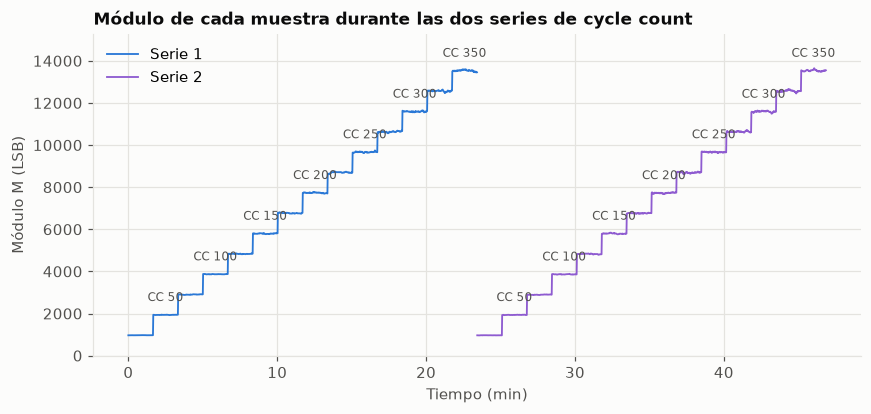

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for b in BARRIDOS:
    bloque = datos[datos["barrido"] == b]
    e = ESTILO[f"Serie {b}"]
    ax.plot(bloque["t_s"] / 60, bloque["M_LSB"], color=e["color"], lw=1.2, label=f"Serie {b}")
    for cc_i, sub in bloque.groupby("cycle_count"):
        if cc_i % 50 == 0:
            ax.annotate(f"CC {cc_i}", (sub["t_s"].mean() / 60, sub["M_LSB"].mean()),
                        xytext=(0, 9), textcoords="offset points",
                        ha="center", fontsize=8, color=TINTA2)
ax.set_xlabel("Tiempo (min)")
ax.set_ylabel("Módulo M (LSB)")
ax.set_title("Módulo de cada muestra durante las dos series de cycle count")
ax.set_ylim(0, datos["M_LSB"].max() * 1.12)
ax.legend(loc="upper left")
plt.show()

## 2. Incertidumbre tipo A

Para el *cycle count* $i$ hay $N$ muestras $M_{i,1},\dots,M_{i,N}$. La mejor estimación del módulo es la media aritmética

$$
\bar M_i = \frac{1}{N}\sum_{k=1}^{N} M_{i,k}, \tag{3}
$$

y la dispersión de las lecturas individuales se estima con la desviación estándar experimental

$$
s_i = \sqrt{\frac{1}{N-1}\sum_{k=1}^{N}\left(M_{i,k}-\bar M_i\right)^2}. \tag{4}
$$

El divisor $N-1$ (y no $N$) se usa porque la media $\bar M_i$ se obtuvo de los mismos datos, lo que deja $N-1$ grados de libertad.

La incertidumbre tipo A es la desviación estándar **de la media**. Si las $N$ lecturas son independientes y cada una tiene varianza $\sigma_i^2$, la varianza de la suma es la suma de las varianzas, y un factor constante sale al cuadrado:

$$
\begin{aligned}
\operatorname{Var}\!\left(\bar M_i\right)
 &= \operatorname{Var}\!\left(\frac{1}{N}\sum_{k=1}^{N} M_{i,k}\right)
  = \frac{1}{N^2}\sum_{k=1}^{N}\operatorname{Var}\!\left(M_{i,k}\right) \\
 &= \frac{1}{N^2}\,N\,\sigma_i^2
  = \frac{\sigma_i^2}{N}.
\end{aligned}
$$

Tomando la raíz y estimando $\sigma_i$ con $s_i$:

$$
u_A\!\left(\bar M_i\right) = \frac{s_i}{\sqrt{N}}. \tag{5}
$$

**Supuestos de (5).** (a) Las lecturas son independientes entre sí. (b) El campo es estacionario durante las 100 muestras. El supuesto (a) se puede comprobar con los datos, y se hace a continuación.

### 2.1 Comprobación de independencia y corrección de $u_A$

Si el campo ambiente fluctúa lentamente, una lectura se parece a la anterior y las muestras dejan de ser independientes. Esto se mide con el coeficiente de autocorrelación de un paso,

$$
r_{1,i}=\frac{\displaystyle\sum_{k=1}^{N-1}\left(M_{i,k}-\bar M_i\right)\left(M_{i,k+1}-\bar M_i\right)}{\displaystyle\sum_{k=1}^{N}\left(M_{i,k}-\bar M_i\right)^2}, \tag{5a}
$$

que vale aproximadamente 0 para lecturas independientes y se acerca a 1 cuando lecturas consecutivas están muy correlacionadas.

Cuando hay correlación, la varianza de la media ya no es $\sigma_i^2/N$. Partiendo de la definición y usando que la varianza de una suma es la suma de todas las covarianzas:

$$
\operatorname{Var}\!\left(\bar M_i\right)=\frac{1}{N^2}\sum_{j=1}^{N}\sum_{k=1}^{N}\operatorname{Cov}\!\left(M_{i,j},M_{i,k}\right)
=\frac{\sigma_i^2}{N^2}\sum_{j=1}^{N}\sum_{k=1}^{N}\rho_{|j-k|},
$$

donde $\rho_\ell$ es la correlación entre lecturas separadas $\ell$ pasos ($\rho_0=1$). En la doble suma hay $N$ términos con $\ell=0$ y $2(N-\ell)$ términos con separación $\ell\ge1$ (los pares $(j,k)$ y $(k,j)$), de modo que

$$
\operatorname{Var}\!\left(\bar M_i\right)=\frac{\sigma_i^2}{N^2}\left[N+2\sum_{\ell=1}^{N-1}(N-\ell)\rho_\ell\right]
=\frac{\sigma_i^2}{N}\left[1+2\sum_{\ell=1}^{N-1}\left(1-\frac{\ell}{N}\right)\rho_\ell\right].
$$

Esta expresión es exacta. Para evaluarla se hacen dos aproximaciones:

- **Modelo de la correlación.** Se supone que decae geométricamente, $\rho_\ell=r_1^{\,\ell}$ (proceso autorregresivo de primer orden). Es una hipótesis sobre la fluctuación del campo.
- **Bloque largo frente al tiempo de correlación.** Los términos que contribuyen son los de $\ell\lesssim\tau$, con $\tau=-1/\ln r_1$ el número de pasos en que la correlación cae a $1/e$. Si $\tau\ll N$, en esos términos $1-\ell/N\approx1$ y la suma se puede extender hasta infinito. El parámetro pequeño es $\tau/N$.

Con ambas, la suma es una serie geométrica de razón $r_1$ con $|r_1|<1$:

$$
\sum_{\ell=1}^{\infty}r_1^{\,\ell}=\frac{r_1}{1-r_1}
\quad\Longrightarrow\quad
1+\frac{2r_1}{1-r_1}=\frac{1-r_1+2r_1}{1-r_1}=\frac{1+r_1}{1-r_1}.
$$

Por lo tanto

$$
\operatorname{Var}\!\left(\bar M_i\right)\approx\frac{\sigma_i^2}{N}\cdot\frac{1+r_{1,i}}{1-r_{1,i}}
\quad\Longrightarrow\quad
u_{A,\text{corr}}\!\left(\bar M_i\right)=\frac{s_i}{\sqrt{N_{\text{ef},i}}},\qquad
N_{\text{ef},i}=N\,\frac{1-r_{1,i}}{1+r_{1,i}}. \tag{5b}
$$

$N_{\text{ef}}$ es el número de lecturas efectivamente independientes. Para $r_1=0$ se recupera (5). Si $r_{1,i}\le0$ se usa $N_{\text{ef}}=N$ (no se reduce la incertidumbre por debajo de la fórmula estándar).

**Alcance de la corrección.** Con $r_1\approx0{,}9$ resulta $\tau\approx9{,}5$ pasos y $\tau/N\approx0{,}1$: la segunda aproximación tiene un error del orden de 10 %, y $r_1$ mismo se estima con solo 100 muestras. La corrección (5b) debe leerse como una estimación del orden de magnitud correcto de $u_A$, no como un valor exacto. Aun así es más realista que (5), que con lecturas tan correlacionadas subestima la incertidumbre de la media varias veces.

En lo que sigue se informan ambas, $u_A$ (fórmula estándar) y $u_{A,\text{corr}}$, y **se usa $u_{A,\text{corr}}$** como incertidumbre tipo A del módulo medio.

## 3. $2\sigma$ e intervalo de confianza

En este análisis la incertidumbre del módulo medio es únicamente la de tipo A (no se incluyen contribuciones tipo B):

$$
u\!\left(\bar M_i\right)=u_{A,\text{corr}}\!\left(\bar M_i\right)=\frac{s_i}{\sqrt{N_{\text{ef},i}}}. \tag{6}
$$

La incertidumbre expandida con factor de cobertura $k=2$ ("$2\sigma$") es

$$
U_i = k\,u\!\left(\bar M_i\right)=2\,u\!\left(\bar M_i\right), \tag{7}
$$

y el intervalo de confianza del módulo medio es

$$
\bar M_i - U_i \;\le\; M_i \;\le\; \bar M_i + U_i . \tag{8}
$$

Para una distribución normal, $k=2$ corresponde a un nivel de confianza de 95,45 %. Con 99 grados de libertad el factor de Student para 95 % sería 1,984; con las pocas lecturas efectivamente independientes de la sección 2.1 es mayor (por ejemplo, 2,78 para 4 grados de libertad). Se mantiene $k=2$ como convención "$2\sigma$", sabiendo que el nivel de confianza real es algo menor que 95 %.

Se tabula además $2s_i$, el $2\sigma$ de las **lecturas individuales**: el intervalo $\bar M_i\pm 2s_i$ contiene aproximadamente el 95 % de las muestras de ese *cycle count*. No hay que confundirlo con (8), que es el intervalo de la **media** y es $\sqrt{N_{\text{ef}}}$ veces más angosto.

**Aplicación a las dos series.** Las ecuaciones (3) a (8) se aplican por separado a cada serie: para cada *cycle count* $i$ y cada serie $j\in\{1,2\}$ se obtienen $\bar M_i^{(j)}$, $s_i^{(j)}$, $r_{1,i}^{(j)}$ y $u\!\left(\bar M_i^{(j)}\right)$.

In [4]:
def autocorr_1(m):
    # Coeficiente de autocorrelacion de un paso, ecuacion (5a)
    d = m.to_numpy() - m.mean()
    return np.sum(d[:-1] * d[1:]) / np.sum(d * d)


def estadistica(bloque):
    """Estadistica tipo A del modulo por cycle count, ecuaciones (3) a (8)."""
    g = bloque.groupby("cycle_count")["M_LSB"]
    res = pd.DataFrame({"N": g.size(), "M_media": g.mean(), "s": g.std(ddof=1)})   # (3) y (4)
    res["u_A"] = res["s"] / np.sqrt(res["N"])                                      # (5)
    res["r1"] = g.apply(autocorr_1)                                                # (5a)
    r1_pos = res["r1"].clip(lower=0.0)
    res["N_ef"] = res["N"] * (1 - r1_pos) / (1 + r1_pos)                           # (5b)
    res["u_A_corr"] = res["s"] / np.sqrt(res["N_ef"])                              # (5b) y (6)
    res["U_2sigma"] = K * res["u_A_corr"]                                          # (7)
    res["IC_inf"] = res["M_media"] - res["U_2sigma"]                               # (8)
    res["IC_sup"] = res["M_media"] + res["U_2sigma"]
    res["U_rel_%"] = 100 * res["U_2sigma"] / res["M_media"]
    res["M/CC"] = res["M_media"] / res.index
    return res


FMT_RES = {"M_media": "{:.2f}", "s": "{:.2f}", "u_A": "{:.3f}", "r1": "{:.2f}", "N_ef": "{:.1f}",
           "u_A_corr": "{:.3f}", "U_2sigma": "{:.3f}", "IC_inf": "{:.2f}", "IC_sup": "{:.2f}",
           "U_rel_%": "{:.3f}", "M/CC": "{:.3f}"}

res = {b: estadistica(datos[datos["barrido"] == b]) for b in BARRIDOS}
assert res[BARRIDOS[0]].index.equals(res[BARRIDOS[1]].index), "las series no tienen los mismos cycle counts"
for b in BARRIDOS:
    display(res[b].style.format(FMT_RES).set_caption(f"Serie {b}"))

,N,M_media,s,u_A,r1,N_ef,u_A_corr,U_2sigma,IC_inf,IC_sup,U_rel_%,M/CC
cycle_count,,,,,,,,,,,,
25,100,969.44,2.20,0.220,0.89,6.0,0.899,1.799,967.64,971.24,0.186,38.778
50,100,1935.39,4.95,0.495,0.85,8.4,1.713,3.426,1931.97,1938.82,0.177,38.708
75,100,2900.83,9.58,0.958,0.92,4.3,4.634,9.267,2891.56,2910.10,0.319,38.678
100,100,3867.83,5.77,0.577,0.82,10.0,1.828,3.656,3864.18,3871.49,0.095,38.678
125,100,4832.58,9.33,0.933,0.79,11.9,2.709,5.417,4827.17,4838.00,0.112,38.661
150,100,5795.08,14.08,1.408,0.87,6.8,5.406,10.812,5784.26,5805.89,0.187,38.634
175,100,6767.42,14.58,1.458,0.87,6.7,5.626,11.252,6756.17,6778.67,0.166,38.671
200,100,7731.36,17.30,1.730,0.86,7.4,6.378,12.756,7718.60,7744.11,0.165,38.657
225,100,8698.11,26.88,2.688,0.93,3.8,13.824,27.648,8670.46,8725.76,0.318,38.658


,N,M_media,s,u_A,r1,N_ef,u_A_corr,U_2sigma,IC_inf,IC_sup,U_rel_%,M/CC
cycle_count,,,,,,,,,,,,
25,100,966.18,2.01,0.201,0.64,21.6,0.431,0.862,965.31,967.04,0.089,38.647
50,100,1934.12,4.66,0.466,0.81,10.6,1.430,2.860,1931.26,1936.98,0.148,38.682
75,100,2892.72,7.78,0.778,0.91,4.5,3.667,7.333,2885.38,2900.05,0.254,38.570
100,100,3861.82,7.53,0.753,0.84,8.9,2.524,5.048,3856.77,3866.86,0.131,38.618
125,100,4826.28,14.11,1.411,0.91,4.7,6.502,13.005,4813.27,4839.28,0.269,38.610
150,100,5795.99,17.39,1.739,0.91,4.6,8.136,16.273,5779.72,5812.26,0.281,38.640
175,100,6762.24,11.53,1.153,0.73,15.8,2.905,5.810,6756.42,6768.05,0.086,38.641
200,100,7724.38,19.89,1.989,0.85,8.3,6.913,13.826,7710.56,7738.21,0.179,38.622
225,100,8692.73,27.81,2.781,0.85,7.8,9.942,19.884,8672.84,8712.61,0.229,38.634


## 4. Promedio de las dos series

**Definición.** Para cada *cycle count* $i$ se dispone de dos módulos medios, $\bar M_i^{(1)}$ y $\bar M_i^{(2)}$, uno por serie. El promedio de las dos series es su media aritmética:

$$
\bar M_i^{(p)}=\frac{\bar M_i^{(1)}+\bar M_i^{(2)}}{2}. \tag{8a}
$$

Se usa la media simple (y no una ponderada con $1/u^2$) porque las dos series tienen el mismo número de muestras por *cycle count*, y porque los pesos se construirían con incertidumbres que a su vez están estimadas con pocas lecturas efectivamente independientes (sección 2.1). Como las dos series tienen $N=100$ muestras, (8a) coincide además con la media de las 200 muestras del *cycle count* $i$:

$$
\frac{1}{2N}\left(\sum_{k=1}^{N}M_{i,k}^{(1)}+\sum_{k=1}^{N}M_{i,k}^{(2)}\right)
=\frac{1}{2}\left(\frac{1}{N}\sum_{k=1}^{N}M_{i,k}^{(1)}+\frac{1}{N}\sum_{k=1}^{N}M_{i,k}^{(2)}\right)
=\frac{\bar M_i^{(1)}+\bar M_i^{(2)}}{2}.
$$

**Incertidumbre.** $\bar M_i^{(p)}$ es función de dos magnitudes. Sus derivadas parciales son

$$
\left(\frac{\partial \bar M_i^{(p)}}{\partial \bar M_i^{(1)}}\right)_{\bar M_i^{(2)}}=\frac12,\qquad
\left(\frac{\partial \bar M_i^{(p)}}{\partial \bar M_i^{(2)}}\right)_{\bar M_i^{(1)}}=\frac12 .
$$

Los dos bloques de muestras de un mismo *cycle count* están separados unos 23 minutos, mucho más que el tiempo de correlación de las lecturas (del orden de 10 s, sección 2.1), por lo que se tratan como independientes y la ley de propagación no lleva término de covarianza:

$$
\begin{aligned}
u^2\!\left(\bar M_i^{(p)}\right)
&=\left(\frac12\right)^2u^2\!\left(\bar M_i^{(1)}\right)+\left(\frac12\right)^2u^2\!\left(\bar M_i^{(2)}\right)
=\frac14\left[u^2\!\left(\bar M_i^{(1)}\right)+u^2\!\left(\bar M_i^{(2)}\right)\right] \\
\Longrightarrow\quad
u\!\left(\bar M_i^{(p)}\right)&=\frac12\sqrt{u^2\!\left(\bar M_i^{(1)}\right)+u^2\!\left(\bar M_i^{(2)}\right)},
\end{aligned}
\tag{8b}
$$

donde cada $u\!\left(\bar M_i^{(j)}\right)$ es la incertidumbre tipo A corregida (6). Si las dos fueran iguales a $u$, (8b) da $\tfrac12\sqrt{2u^2}=u/\sqrt2$: promediar dos series reduce la incertidumbre en un factor $\sqrt2$. La independencia entre series es un **supuesto**: una variación del campo más lenta que 23 minutos afectaría a las dos series de forma distinta y no está contenida en (8b); eso es lo que comprueba (8d).

**El promedio sigue siendo proporcional a la ganancia.** Si el campo durante la serie $j$ es $B^{(j)}$, por (2) $\bar M_i^{(j)}=G_i\,B^{(j)}$, y sustituyendo en (8a):

$$
\bar M_i^{(p)}=\frac{G_i\,B^{(1)}+G_i\,B^{(2)}}{2}=G_i\,\frac{B^{(1)}+B^{(2)}}{2}\equiv G_i\,B^{(p)}. \tag{8c}
$$

El promedio se comporta entonces como una serie más, medida con el campo medio $B^{(p)}$, y todo el análisis de las secciones 6 y 7 se le aplica sin cambios, con $u\!\left(\bar M_i^{(p)}\right)$ de (8b) como incertidumbre.

**Compatibilidad entre las dos series.** Antes de promediar conviene comprobar que las dos series miden lo mismo. La diferencia y su incertidumbre (misma propagación que en (8b), ahora con derivadas parciales $+1$ y $-1$) son

$$
d_i=\bar M_i^{(1)}-\bar M_i^{(2)},\qquad
u(d_i)=\sqrt{(+1)^2u^2\!\left(\bar M_i^{(1)}\right)+(-1)^2u^2\!\left(\bar M_i^{(2)}\right)}
=\sqrt{u^2\!\left(\bar M_i^{(1)}\right)+u^2\!\left(\bar M_i^{(2)}\right)}. \tag{8d}
$$

Si las series son compatibles, $|d_i|/u(d_i)$ debe ser menor que 2 en la gran mayoría de los *cycle counts*.

In [5]:
r1_, r2_ = res[BARRIDOS[0]], res[BARRIDOS[1]]
cc = r1_.index.to_numpy(dtype=float)
M1, u1 = r1_["M_media"].to_numpy(), r1_["u_A_corr"].to_numpy()
M2, u2 = r2_["M_media"].to_numpy(), r2_["u_A_corr"].to_numpy()

Mp = (M1 + M2) / 2                      # ecuacion (8a)
up = 0.5 * np.sqrt(u1**2 + u2**2)       # ecuacion (8b)
d = M1 - M2                             # ecuacion (8d)
ud = np.sqrt(u1**2 + u2**2)

# Las tres "series" que se analizan en adelante: modulo medio y su incertidumbre tipo A
SERIES = {"Serie 1": (M1, u1), "Serie 2": (M2, u2), "Promedio": (Mp, up)}

prom = pd.DataFrame({"M_serie1": M1, "u_serie1": u1, "M_serie2": M2, "u_serie2": u2,
                     "M_promedio": Mp, "u_promedio": up, "U_prom (2 sigma)": K * up,
                     "d = M1 - M2": d, "d (%)": 100 * d / Mp, "d / u(d)": d / ud},
                    index=r1_.index)
print(f"|d|/u(d) < 2 en {np.sum(np.abs(d / ud) < 2)} de {len(d)} cycle counts;  "
      f"media de d = {np.mean(100 * d / Mp):+.3f} %")
prom.style.format({"M_serie1": "{:.2f}", "u_serie1": "{:.2f}", "M_serie2": "{:.2f}",
                   "u_serie2": "{:.2f}", "M_promedio": "{:.2f}", "u_promedio": "{:.2f}",
                   "U_prom (2 sigma)": "{:.2f}", "d = M1 - M2": "{:+.2f}", "d (%)": "{:+.3f}",
                   "d / u(d)": "{:+.2f}"})

|d|/u(d) < 2 en 13 de 14 cycle counts;  media de d = +0.082 %


,M_serie1,u_serie1,M_serie2,u_serie2,M_promedio,u_promedio,U_prom (2 sigma),d = M1 - M2,d (%),d / u(d)
cycle_count,,,,,,,,,,
25,969.44,0.90,966.18,0.43,967.81,0.50,1.00,+3.26,+0.337,+3.27
50,1935.39,1.71,1934.12,1.43,1934.75,1.12,2.23,+1.27,+0.066,+0.57
75,2900.83,4.63,2892.72,3.67,2896.77,2.95,5.91,+8.11,+0.280,+1.37
100,3867.83,1.83,3861.82,2.52,3864.83,1.56,3.12,+6.02,+0.156,+1.93
125,4832.58,2.71,4826.28,6.50,4829.43,3.52,7.04,+6.31,+0.131,+0.90
150,5795.08,5.41,5795.99,8.14,5795.53,4.88,9.77,-0.92,-0.016,-0.09
175,6767.42,5.63,6762.24,2.91,6764.83,3.17,6.33,+5.19,+0.077,+0.82
200,7731.36,6.38,7724.38,6.91,7727.87,4.70,9.41,+6.97,+0.090,+0.74
225,8698.11,13.82,8692.73,9.94,8695.42,8.51,17.03,+5.38,+0.062,+0.32


## 5. Qué dice el datasheet

El fabricante indica que la ganancia crece linealmente con el *cycle count* $C$. La relación que usa el código de ejemplo de PNI, y que reproduce los valores tabulados, es

$$
G_{\text{ds}}(C)=\alpha\,C+\beta,\qquad \alpha=0{,}3671\ \frac{\text{LSB}}{\mu\text{T}},\quad \beta=1{,}5\ \frac{\text{LSB}}{\mu\text{T}}. \tag{9}
$$

Los valores tabulados de ganancia son 20, 38 y 75 LSB/µT para $C=50$, 100 y 200; la expresión (9) da $0{,}3671\cdot50+1{,}5=19{,}86$, $0{,}3671\cdot100+1{,}5=38{,}21$ y $0{,}3671\cdot200+1{,}5=74{,}92$, que redondeados coinciden con la tabla.

La sensibilidad es el inverso de la ganancia. Con $1\ \mu\text{T}=1000\ \text{nT}$:

$$
S_{\text{ds}}(C)=\frac{1}{G_{\text{ds}}(C)}=\frac{1000}{\alpha\,C+\beta}\ \frac{\text{nT}}{\text{LSB}}. \tag{10}
$$

Para $C=50$, 100 y 200 resulta $1000/19{,}86=50{,}4$, $1000/38{,}21=26{,}2$ y $1000/74{,}92=13{,}3$ nT/LSB, que coinciden con los 50, 26 y 13 nT que tabula el datasheet como sensibilidad.

Estos números están escritos como constantes en la primera celda (`DS_PENDIENTE`, `DS_OFFSET`, `DS_TABLA`) y **conviene verificarlos contra tu copia del datasheet**: se transcribieron del código original del proyecto y de los valores nominales conocidos del RM3100.

Combinando (2) con (9), si el datasheet es correcto y el campo $B$ es el mismo durante todo el barrido, el módulo medio debe cumplir

$$
\bar M_i = B\,G_{\text{ds}}(C_i)=B\left(\alpha\,C_i+\beta\right). \tag{11}
$$

**Supuesto.** $B$ constante durante los ~23 minutos de cada serie. Es una hipótesis; se puede juzgar con el cociente $\bar M_i/C_i$ (columna `M/CC` de la sección 3), porque una deriva del campo aparecería en él como una tendencia, y con la diferencia entre las dos series (sección 4).

## 6. Ganancia y sensibilidad por *cycle count*

De (2), la ganancia en el *cycle count* $i$ es

$$
G_i=\frac{\bar M_i}{B}. \tag{15}
$$

**Estimación de $B$.** $B$ es la única incógnita y es común a los 14 puntos. Se elige el valor que mejor ajusta el modelo del datasheet (11) a los datos por mínimos cuadrados ponderados, es decir, el que minimiza

$$
\chi^2(B)=\sum_{i=1}^{14}\frac{\left(\bar M_i-B\,G_{\text{ds},i}\right)^2}{u_i^2},\qquad G_{\text{ds},i}\equiv G_{\text{ds}}(C_i),\quad u_i\equiv u\!\left(\bar M_i\right). \tag{16}
$$

Cada término se divide por $u_i^2$ para que los puntos más precisos pesen más. Derivando respecto de $B$ (regla de la cadena en cada término) e igualando a cero:

$$
\begin{aligned}
\frac{d\chi^2}{dB}&=\sum_i\frac{2\left(\bar M_i-B\,G_{\text{ds},i}\right)\left(-G_{\text{ds},i}\right)}{u_i^2}=0 \\
\Longrightarrow\quad &\sum_i\frac{G_{\text{ds},i}\bar M_i}{u_i^2}-B\sum_i\frac{G_{\text{ds},i}^2}{u_i^2}=0 \\
\Longrightarrow\quad &\hat B=\frac{\displaystyle\sum_i G_{\text{ds},i}\bar M_i/u_i^2}{\displaystyle\sum_i G_{\text{ds},i}^2/u_i^2}.
\end{aligned}
\tag{17}
$$

Es un mínimo porque la segunda derivada, $d^2\chi^2/dB^2=2\sum_i G_{\text{ds},i}^2/u_i^2$, es positiva.

El mismo cálculo con $G_{\text{ds},i}$ reemplazado por $C_i$ ajusta el **modelo proporcional** $\bar M_i=\kappa\,C_i$ (ganancia proporcional al *cycle count*, sin término constante):

$$
\hat\kappa=\frac{\displaystyle\sum_i C_i\bar M_i/u_i^2}{\displaystyle\sum_i C_i^2/u_i^2}. \tag{18}
$$

Ambos modelos tienen un solo parámetro libre, de modo que quedan $\nu=14-1=13$ grados de libertad. Si un modelo describe los datos dentro de sus incertidumbres, $\chi^2_{\min}/\nu$ es del orden de 1; un valor mucho mayor indica que el modelo no es compatible con los datos.

**Ganancia e intervalo.** Con $\hat B$ fijo, la ganancia y su incertidumbre expandida son

$$
G_i=\frac{\bar M_i}{\hat B},\qquad U(G_i)=\frac{U_i}{\hat B}=\frac{2\,u\!\left(\bar M_i\right)}{\hat B}, \tag{19}
$$

porque $G_i$ es $\bar M_i$ multiplicado por la constante $1/\hat B$ y la incertidumbre escala con el mismo factor.

**Sensibilidad e intervalo.** La sensibilidad es el inverso de la ganancia; en nT/LSB:

$$
S_i=\frac{1000}{G_i}=\frac{1000\,\hat B}{\bar M_i}\ \frac{\text{nT}}{\text{LSB}}. \tag{20}
$$

Su incertidumbre se obtiene propagando la de $G_i$. Derivando (20) respecto de $G_i$:

$$
\frac{dS_i}{dG_i}=\frac{d}{dG_i}\left(1000\,G_i^{-1}\right)=-1000\,G_i^{-2}=-\frac{1000}{G_i^2}=-\frac{S_i}{G_i},
$$

y a primer orden

$$
U(S_i)=\left|\frac{dS_i}{dG_i}\right|U(G_i)=S_i\,\frac{U(G_i)}{G_i}=S_i\,\frac{U_i}{\bar M_i}, \tag{21}
$$

donde en el último paso se usó (19): $U(G_i)/G_i=(U_i/\hat B)/(\bar M_i/\hat B)=U_i/\bar M_i$. La sensibilidad tiene entonces la misma incertidumbre relativa que el módulo medio. La aproximación a primer orden es válida porque el parámetro pequeño $U_i/\bar M_i$ es menor que $0{,}5\,\%$ en todos los *cycle counts* (columna `U_rel_%` de la sección 3); los términos despreciados son del orden de su cuadrado.

El intervalo de confianza es $S_i\pm U(S_i)$, y la desviación relativa respecto del datasheet es

$$
\Delta_i=100\,\frac{S_i-S_{\text{ds}}(C_i)}{S_{\text{ds}}(C_i)}\ \%,\qquad U(\Delta_i)=100\,\frac{U(S_i)}{S_{\text{ds}}(C_i)}\ \%. \tag{22}
$$

**Alcance del resultado.** $\hat B$ se usa como un factor de escala fijo, común a todos los *cycle counts*; su propia incertidumbre no se propaga. En consecuencia, $U(G_i)$ y $U(S_i)$ reflejan solo la incertidumbre tipo A del módulo, y lo que este análisis valida es la **dependencia de la ganancia y de la sensibilidad con el *cycle count***. El valor absoluto de la escala (por ejemplo, si todas las ganancias fueran un 5 % mayores) no se puede validar sin una medición independiente del campo. La sección 9 repite el cálculo sustituyendo $\hat B$ por el campo del modelo IGRF-14.

**Aplicación a las dos series y al promedio.** Las ecuaciones (16) a (22) se aplican tres veces: a la serie 1, a la serie 2 y al promedio (8a)–(8b). Cada una tiene **su propio** $\hat B$, porque el campo pudo cambiar entre una serie y la otra; para el promedio, $\hat B^{(p)}$ estima el campo medio $B^{(p)}$ de (8c).

In [6]:
G_ds = DS_PENDIENTE * cc + DS_OFFSET          # ecuacion (9)
S_ds = 1000.0 / G_ds                          # ecuacion (10)
nu = len(cc) - 1


def ajustar_campo(M, u):
    """Ajuste de un parametro: B (modelo datasheet, ec. 17) y kappa (modelo proporcional, ec. 18)."""
    w = 1.0 / u**2
    B = np.sum(w * G_ds * M) / np.sum(w * G_ds**2)
    kappa = np.sum(w * cc * M) / np.sum(w * cc**2)
    return {"B_hat (uT)": B, "chi2/nu datasheet": np.sum(w * (M - B * G_ds)**2) / nu,
            "kappa (LSB/cuenta)": kappa, "chi2/nu proporcional": np.sum(w * (M - kappa * cc)**2) / nu}


ajuste_B = pd.DataFrame({nombre: ajustar_campo(M, u) for nombre, (M, u) in SERIES.items()}).T
B_HAT = ajuste_B["B_hat (uT)"].to_dict()
ajuste_B.style.format({"B_hat (uT)": "{:.2f}", "chi2/nu datasheet": "{:.1f}",
                       "kappa (LSB/cuenta)": "{:.3f}", "chi2/nu proporcional": "{:.2f}"})

,B_hat (uT),chi2/nu datasheet,kappa (LSB/cuenta),chi2/nu proporcional
Serie 1,101.75,1858.5,38.667,1.15
Serie 2,100.07,6054.0,38.649,0.74
Promedio,100.92,5176.4,38.660,1.10


### 6.1 Por qué $\hat B$ puede diferir entre series que miden lo mismo

La tabla anterior muestra que $\hat\kappa$ es casi igual en las dos series, mientras que $\hat B$ difiere bastante más. La causa está en la forma de (17). Multiplicando y dividiendo cada término del numerador por $G_{\text{ds},i}$:

$$
\hat B=\frac{\displaystyle\sum_i \frac{G_{\text{ds},i}\,\bar M_i}{u_i^2}}{\displaystyle\sum_j \frac{G_{\text{ds},j}^2}{u_j^2}}
=\frac{\displaystyle\sum_i \frac{G_{\text{ds},i}^2}{u_i^2}\cdot\frac{\bar M_i}{G_{\text{ds},i}}}{\displaystyle\sum_j \frac{G_{\text{ds},j}^2}{u_j^2}}
=\sum_i p_i\,B_i,
\qquad
B_i\equiv\frac{\bar M_i}{G_{\text{ds},i}},\qquad
p_i\equiv\frac{G_{\text{ds},i}^2/u_i^2}{\displaystyle\sum_j G_{\text{ds},j}^2/u_j^2}. \tag{17a}
$$

Como $p_i\ge0$ y $\sum_ip_i=1$, $\hat B$ es una **media ponderada** de los campos $B_i$ que el datasheet asignaría a cada *cycle count* por separado, con pesos proporcionales a $\left(G_{\text{ds},i}/u_i\right)^2$.

Si el modelo del datasheet describiera los datos, todos los $B_i$ serían iguales dentro de su incertidumbre y los pesos no importarían. Pero los datos siguen el modelo proporcional $\bar M_i=\kappa\,C_i$ (su $\chi^2/\nu$ es del orden de 1, frente a miles para el datasheet), y entonces

$$
B_i=\frac{\kappa\,C_i}{\alpha\,C_i+\beta}=\frac{\kappa}{\alpha+\beta/C_i}, \tag{17b}
$$

que **crece** con el *cycle count*: de $\kappa/(\alpha+\beta/25)$ a $\kappa/(\alpha+\beta/350)$. $\hat B$ es un promedio de valores que no son iguales entre sí, y el resultado depende de cómo se reparten los pesos $p_i$, es decir, de qué *cycle counts* tuvieron por azar una incertidumbre $u_i$ pequeña en esa serie. Por eso dos series con los mismos $\bar M_i$ pueden dar $\hat B$ distintos. La celda siguiente tabula $B_i$ y $p_i$ para comprobarlo.

In [7]:
t17 = pd.DataFrame(index=r1_.index)
for nombre, (M, u) in SERIES.items():
    peso = (G_ds / u)**2
    t17[f"B_i {nombre} (µT)"] = M / G_ds                 # ecuacion (17a)
    t17[f"p_i {nombre} (%)"] = 100 * peso / peso.sum()
    assert np.isclose(np.sum(peso / peso.sum() * M / G_ds), B_HAT[nombre])   # (17a) reproduce (17)
t17["B_i modelo proporcional (17b)"] = ajuste_B.loc["Promedio", "kappa (LSB/cuenta)"] / (DS_PENDIENTE + DS_OFFSET / cc)
print("Diferencia relativa entre series:  kappa: "
      f"{100 * (ajuste_B.loc['Serie 1', 'kappa (LSB/cuenta)'] / ajuste_B.loc['Serie 2', 'kappa (LSB/cuenta)'] - 1):+.3f} %"
      f"    B_hat: {100 * (B_HAT['Serie 1'] / B_HAT['Serie 2'] - 1):+.2f} %")
t17.style.format("{:.2f}").format("{:.1f}", subset=[c for c in t17 if c.startswith("p_i")])

Diferencia relativa entre series:  kappa: +0.048 %    B_hat: +1.68 %


,B_i Serie 1 (µT),p_i Serie 1 (%),B_i Serie 2 (µT),p_i Serie 2 (%),B_i Promedio (µT),p_i Promedio (%),B_i modelo proporcional (17b)
cycle_count,,,,,,,
25,90.79,6.0,90.49,20.6,90.64,11.8,90.52
50,97.48,5.7,97.41,6.5,97.44,8.2,97.36
75,99.92,1.7,99.64,2.1,99.78,2.5,99.87
100,101.23,18.5,101.07,7.7,101.15,15.5,101.18
125,101.98,13.0,101.85,1.8,101.91,4.7,101.98
150,102.45,4.6,102.47,1.6,102.46,3.5,102.52
175,102.94,5.8,102.86,17.2,102.90,11.1,102.91
200,103.19,5.8,103.10,3.9,103.15,6.5,103.20
225,103.43,1.6,103.36,2.4,103.40,2.5,103.43


In [8]:
def ganancia_sensibilidad(M, u, B):
    """Ganancia (19) y sensibilidad (20)-(22) con el campo B (uT), con U a 2 sigma."""
    G = M / B
    S = 1000.0 / G
    U_S = S * K * u / M
    return {"G": G, "u_G": u / B, "U_G": K * u / B, "S": S, "U_S": U_S,
            "desv_G_%": 100 * (G - G_ds) / G_ds,
            "desv_S_%": 100 * (S - S_ds) / S_ds, "U_desv_S_%": 100 * U_S / S_ds,
            "ds_en_IC": (S_ds >= S - U_S) & (S_ds <= S + U_S)}


GS_HAT = {n: ganancia_sensibilidad(M, u, B_HAT[n]) for n, (M, u) in SERIES.items()}


def tabla(gs, clave, clave_U, nombre_ds, valores_ds):
    t = pd.DataFrame(index=r1_.index)
    for n in gs:
        t[n] = gs[n][clave]
        t[f"U {n}"] = gs[n][clave_U]
    t[nombre_ds] = valores_ds
    return t


tabla_G = tabla(GS_HAT, "G", "U_G", "datasheet", G_ds)
for n in GS_HAT:
    tabla_G[f"desv {n} (%)"] = GS_HAT[n]["desv_G_%"]
display(tabla_G.style.format("{:.3f}").format("{:+.2f}", subset=[c for c in tabla_G if "desv" in c])
        .set_caption("Ganancia (LSB/µT) con B̂ ajustado, U a 2σ"))

tabla_S = tabla(GS_HAT, "S", "U_S", "datasheet", S_ds)
for n in GS_HAT:
    tabla_S[f"desv {n} (%)"] = GS_HAT[n]["desv_S_%"]
    tabla_S[f"ds en IC {n}"] = GS_HAT[n]["ds_en_IC"]
display(tabla_S.style.format("{:.3f}", subset=[c for c in tabla_S if "desv" not in c and "IC" not in c])
        .format("{:+.2f}", subset=[c for c in tabla_S if "desv" in c])
        .set_caption("Sensibilidad (nT/LSB) con B̂ ajustado, U a 2σ"))

,Serie 1,U Serie 1,Serie 2,U Serie 2,Promedio,U Promedio,datasheet,desv Serie 1 (%),desv Serie 2 (%),desv Promedio (%)
cycle_count,,,,,,,,,,
25,9.528,0.018,9.655,0.009,9.589,0.010,10.678,-10.77,-9.57,-10.19
50,19.021,0.034,19.328,0.029,19.170,0.022,19.855,-4.20,-2.65,-3.45
75,28.510,0.091,28.908,0.073,28.702,0.059,29.032,-1.80,-0.43,-1.14
100,38.013,0.036,38.592,0.050,38.294,0.031,38.210,-0.51,+1.00,+0.22
125,47.495,0.053,48.230,0.130,47.852,0.070,47.387,+0.23,+1.78,+0.98
150,56.955,0.106,57.921,0.163,57.425,0.097,56.565,+0.69,+2.40,+1.52
175,66.511,0.111,67.577,0.058,67.029,0.063,65.742,+1.17,+2.79,+1.96
200,75.985,0.125,77.192,0.138,76.571,0.093,74.920,+1.42,+3.03,+2.20
225,85.486,0.272,86.869,0.199,86.158,0.169,84.097,+1.65,+3.30,+2.45


,Serie 1,U Serie 1,Serie 2,U Serie 2,Promedio,U Promedio,datasheet,desv Serie 1 (%),ds en IC Serie 1,desv Serie 2 (%),ds en IC Serie 2,desv Promedio (%),ds en IC Promedio
cycle_count,,,,,,,,,,,,,
25,104.957,0.195,103.570,0.092,104.282,0.107,93.655,+12.07,False,+10.59,False,+11.35,False
50,52.573,0.093,51.738,0.077,52.164,0.060,50.365,+4.38,False,+2.73,False,+3.57,False
75,35.076,0.112,34.593,0.088,34.840,0.071,34.444,+1.83,False,+0.43,False,+1.15,False
100,26.306,0.025,25.912,0.034,26.114,0.021,26.171,+0.52,False,-0.99,False,-0.22,False
125,21.055,0.024,20.734,0.056,20.898,0.030,21.103,-0.23,False,-1.75,False,-0.97,False
150,17.558,0.033,17.265,0.048,17.414,0.029,17.679,-0.68,False,-2.34,False,-1.50,False
175,15.035,0.025,14.798,0.013,14.919,0.014,15.211,-1.16,False,-2.71,False,-1.92,False
200,13.161,0.022,12.955,0.023,13.060,0.016,13.348,-1.40,False,-2.94,False,-2.16,False
225,11.698,0.037,11.512,0.026,11.607,0.023,11.891,-1.62,False,-3.19,False,-2.39,False


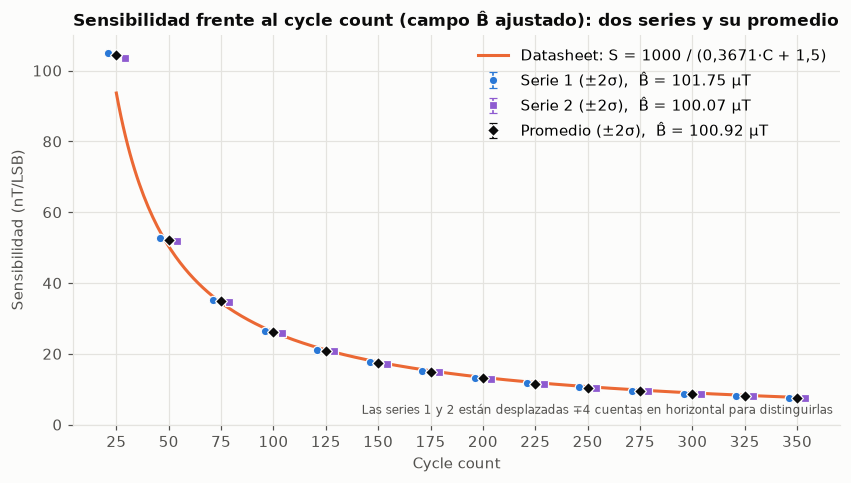

In [9]:
cc_fino = np.linspace(cc.min(), cc.max(), 300)

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(cc_fino, 1000.0 / (DS_PENDIENTE * cc_fino + DS_OFFSET), color=C_DS, lw=2,
        label="Datasheet: S = 1000 / (0,3671·C + 1,5)")
for n, gs in GS_HAT.items():
    puntos(ax, cc, gs["S"], gs["U_S"], n, f"{n} (±2σ),  B̂ = {B_HAT[n]:.2f} µT")
ax.set_xlabel("Cycle count")
ax.set_ylabel("Sensibilidad (nT/LSB)")
ax.set_title("Sensibilidad frente al cycle count (campo B̂ ajustado): dos series y su promedio")
ax.set_xticks(cc)
ax.set_ylim(0, None)
ax.legend(loc="upper right")
ax.text(0.99, 0.02, "Las series 1 y 2 están desplazadas ∓4 cuentas en horizontal para distinguirlas",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=8, color=TINTA2)
plt.show()

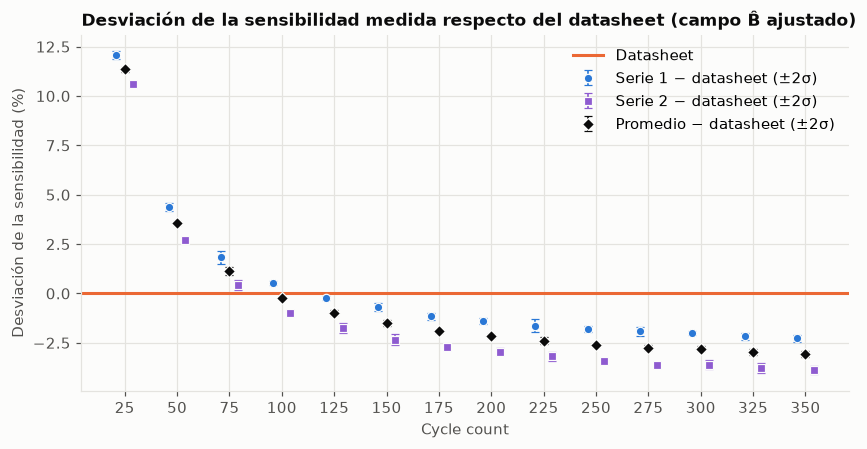

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.axhline(0, color=C_DS, lw=2, label="Datasheet")
for n, gs in GS_HAT.items():
    puntos(ax, cc, gs["desv_S_%"], gs["U_desv_S_%"], n, f"{n} − datasheet (±2σ)")
ax.set_xlabel("Cycle count")
ax.set_ylabel("Desviación de la sensibilidad (%)")
ax.set_title("Desviación de la sensibilidad medida respecto del datasheet (campo B̂ ajustado)")
ax.set_xticks(cc)
ax.legend(loc="upper right")
plt.show()

## 7. Ajuste por mínimos cuadrados de la ganancia y comparación de las dos rectas

El datasheet describe la ganancia con una recta, $G_{\text{ds}}(C)=\alpha C+\beta$. Para comparar, se ajusta a las 14 ganancias medidas una recta con pendiente $a$ y ordenada en el origen $b$ libres:

$$
G(C)=a\,C+b. \tag{23}
$$

**Criterio.** Se usan mínimos cuadrados ponderados: se buscan $a$ y $b$ que minimizan

$$
\chi^2(a,b)=\sum_{i=1}^{14}w_i\left(G_i-a\,C_i-b\right)^2,\qquad w_i=\frac{1}{u^2(G_i)},\quad u(G_i)=\frac{u\!\left(\bar M_i\right)}{\hat B}. \tag{24}
$$

Los pesos $w_i$ hacen que los puntos con menor incertidumbre (tipo A) influyan más. Si todas las incertidumbres fueran iguales se recuperan los mínimos cuadrados ordinarios.

**Ecuaciones normales.** En el mínimo se anulan las dos derivadas parciales. Derivando (24) respecto de $a$ con $b$ constante, y respecto de $b$ con $a$ constante (regla de la cadena en cada término):

$$
\begin{aligned}
\left(\frac{\partial\chi^2}{\partial a}\right)_b&=\sum_i 2\,w_i\left(G_i-a\,C_i-b\right)\left(-C_i\right)=0,\\
\left(\frac{\partial\chi^2}{\partial b}\right)_a&=\sum_i 2\,w_i\left(G_i-a\,C_i-b\right)\left(-1\right)=0.
\end{aligned}
$$

Dividiendo por $-2$, separando las sumas y definiendo

$$
S_w=\sum_i w_i,\quad S_x=\sum_i w_iC_i,\quad S_y=\sum_i w_iG_i,\quad S_{xx}=\sum_i w_iC_i^2,\quad S_{xy}=\sum_i w_iC_iG_i,
$$

las dos condiciones quedan

$$
\begin{aligned}
a\,S_{xx}+b\,S_x&=S_{xy},\\
a\,S_x+b\,S_w&=S_y.
\end{aligned}
\tag{25}
$$

**Solución.** Para despejar $a$ se multiplica la primera ecuación por $S_w$, la segunda por $S_x$, y se restan, con lo que se cancela $b$:

$$
a\,S_wS_{xx}+b\,S_wS_x-a\,S_x^2-b\,S_xS_w=S_wS_{xy}-S_xS_y
\quad\Longrightarrow\quad
a\left(S_wS_{xx}-S_x^2\right)=S_wS_{xy}-S_xS_y .
$$

Para despejar $b$ se multiplica la segunda por $S_{xx}$, la primera por $S_x$, y se restan, con lo que se cancela $a$:

$$
a\,S_xS_{xx}+b\,S_wS_{xx}-a\,S_{xx}S_x-b\,S_x^2=S_{xx}S_y-S_xS_{xy}
\quad\Longrightarrow\quad
b\left(S_wS_{xx}-S_x^2\right)=S_{xx}S_y-S_xS_{xy}.
$$

Con $\Delta\equiv S_wS_{xx}-S_x^2$:

$$
a=\frac{S_wS_{xy}-S_xS_y}{\Delta},\qquad b=\frac{S_{xx}S_y-S_xS_{xy}}{\Delta}. \tag{26}
$$

$\Delta$ es positivo siempre que los $C_i$ no sean todos iguales (desigualdad de Cauchy–Schwarz aplicada a $\sqrt{w_i}$ y $\sqrt{w_i}\,C_i$), de modo que la solución existe y es única. Es un mínimo porque la matriz de segundas derivadas, con elementos $2S_{xx}$, $2S_x$, $2S_x$, $2S_w$, tiene $2S_{xx}>0$ y determinante $4\Delta>0$.

**Incertidumbre de $a$ y $b$.** Según (26), $a$ y $b$ son combinaciones lineales de los $G_i$ (los $C_i$ no tienen incertidumbre). Las derivadas respecto de cada $G_i$ son

$$
\frac{\partial a}{\partial G_i}=\frac{w_i\left(S_wC_i-S_x\right)}{\Delta},\qquad
\frac{\partial b}{\partial G_i}=\frac{w_i\left(S_{xx}-S_xC_i\right)}{\Delta}.
$$

Como los $G_i$ de distintos *cycle counts* son independientes y $u^2(G_i)=1/w_i$, la ley de propagación da para la pendiente

$$
\begin{aligned}
u^2(a)&=\sum_i\left(\frac{\partial a}{\partial G_i}\right)^2\frac{1}{w_i}
=\frac{1}{\Delta^2}\sum_i w_i\left(S_wC_i-S_x\right)^2 \\
&=\frac{1}{\Delta^2}\left(S_w^2S_{xx}-2S_wS_x\,S_x+S_x^2S_w\right)
=\frac{S_w\left(S_wS_{xx}-S_x^2\right)}{\Delta^2}=\frac{S_w}{\Delta},
\end{aligned}
$$

y para la ordenada

$$
\begin{aligned}
u^2(b)&=\sum_i\left(\frac{\partial b}{\partial G_i}\right)^2\frac{1}{w_i}
=\frac{1}{\Delta^2}\sum_i w_i\left(S_{xx}-S_xC_i\right)^2 \\
&=\frac{1}{\Delta^2}\left(S_{xx}^2S_w-2S_{xx}S_x\,S_x+S_x^2S_{xx}\right)
=\frac{S_{xx}\left(S_wS_{xx}-S_x^2\right)}{\Delta^2}=\frac{S_{xx}}{\Delta}.
\end{aligned}
$$

Por lo tanto

$$
u(a)=\sqrt{\frac{S_w}{\Delta}},\qquad u(b)=\sqrt{\frac{S_{xx}}{\Delta}}. \tag{27}
$$

**Comparación con el datasheet.** Se compara $a$ con $\alpha$ y $b$ con $\beta$ mediante la diferencia en unidades de su incertidumbre, $(a-\alpha)/u(a)$ y $(b-\beta)/u(b)$; un valor absoluto mayor que 2 indica que el parámetro del datasheet queda fuera del intervalo $2\sigma$ del ajuste. El ajuste tiene dos parámetros libres, así que quedan $\nu=14-2=12$ grados de libertad.

**Qué depende de $\hat B$ y qué no.** Como $G_i=\bar M_i/\hat B$, tanto $a$ como $b$ son inversamente proporcionales a $\hat B$. La comparación de la pendiente con $\alpha$ depende entonces de la escala elegida. En cambio, que $b$ sea compatible con cero, y el cociente $b/a$, no dependen de $\hat B$.

**Aplicación a las dos series y al promedio.** El ajuste (23)–(27) se hace tres veces, con las ganancias de la serie 1, de la serie 2 y del promedio, cada una con su $\hat B$ de la sección 6.

In [11]:
def ajustar_recta(G, uG):
    """Recta G = a C + b por minimos cuadrados ponderados, ecuaciones (24) a (27)."""
    w = 1.0 / uG**2
    Sw, Sx, Sy = np.sum(w), np.sum(w * cc), np.sum(w * G)
    Sxx, Sxy = np.sum(w * cc**2), np.sum(w * cc * G)
    Delta = Sw * Sxx - Sx**2
    a = (Sw * Sxy - Sx * Sy) / Delta              # ecuacion (26)
    b = (Sxx * Sy - Sx * Sxy) / Delta
    u_a, u_b = np.sqrt(Sw / Delta), np.sqrt(Sxx / Delta)      # ecuacion (27)
    # Comprobacion independiente de (26) con numpy
    a_np, b_np = np.polyfit(cc, G, 1, w=1.0 / uG)
    assert np.isclose(a, a_np) and np.isclose(b, b_np, atol=1e-9)
    return {"a": a, "U_a": K * u_a, "b": b, "U_b": K * u_b,
            "(a-alfa)/u_a": (a - DS_PENDIENTE) / u_a, "(b-beta)/u_b": (b - DS_OFFSET) / u_b,
            "b/a": b / a,
            "chi2/nu ajuste": np.sum(w * (G - a * cc - b)**2) / (len(cc) - 2),
            "chi2/nu datasheet": np.sum(w * (G - G_ds)**2) / len(cc)}


FMT_RECTA = {"a": "{:.5f}", "U_a": "{:.5f}", "b": "{:+.3f}", "U_b": "{:.3f}",
             "(a-alfa)/u_a": "{:+.1f}", "(b-beta)/u_b": "{:+.1f}", "b/a": "{:+.2f}",
             "chi2/nu ajuste": "{:.2f}", "chi2/nu datasheet": "{:.1f}"}

RECTA_HAT = {n: ajustar_recta(gs["G"], gs["u_G"]) for n, gs in GS_HAT.items()}
for n, f in RECTA_HAT.items():
    print(f"{n:9s}: G = ({f['a']:.5f} ± {f['U_a']:.5f})·C + ({f['b']:+.3f} ± {f['U_b']:.3f})   [LSB/µT, ±2σ]")
print(f"Datasheet: G = {DS_PENDIENTE:.4f}·C + {DS_OFFSET:.1f}        (b/a = {DS_OFFSET / DS_PENDIENTE:.2f} cuentas de ciclo)")
pd.DataFrame(RECTA_HAT).T.style.format(FMT_RECTA).set_caption(
    "Rectas ajustadas con B̂ (a en LSB/µT por cuenta de ciclo, b en LSB/µT, U a 2σ)")

Serie 1  : G = (0.37974 ± 0.00022)·C + (+0.034 ± 0.019)   [LSB/µT, ±2σ]
Serie 2  : G = (0.38624 ± 0.00019)·C + (-0.001 ± 0.011)   [LSB/µT, ±2σ]
Promedio : G = (0.38288 ± 0.00017)·C + (+0.017 ± 0.011)   [LSB/µT, ±2σ]
Datasheet: G = 0.3671·C + 1.5        (b/a = 4.09 cuentas de ciclo)


,a,U_a,b,U_b,(a-alfa)/u_a,(b-beta)/u_b,b/a,chi2/nu ajuste,chi2/nu datasheet
Serie 1,0.37974,0.00022,+0.034,0.019,+114.8,-155.4,+0.09,0.15,1725.7
Serie 2,0.38624,0.00019,-0.001,0.011,+199.9,-280.2,-0.00,0.80,5621.5
Promedio,0.38288,0.00017,+0.017,0.011,+187.1,-259.2,+0.04,0.45,4806.7


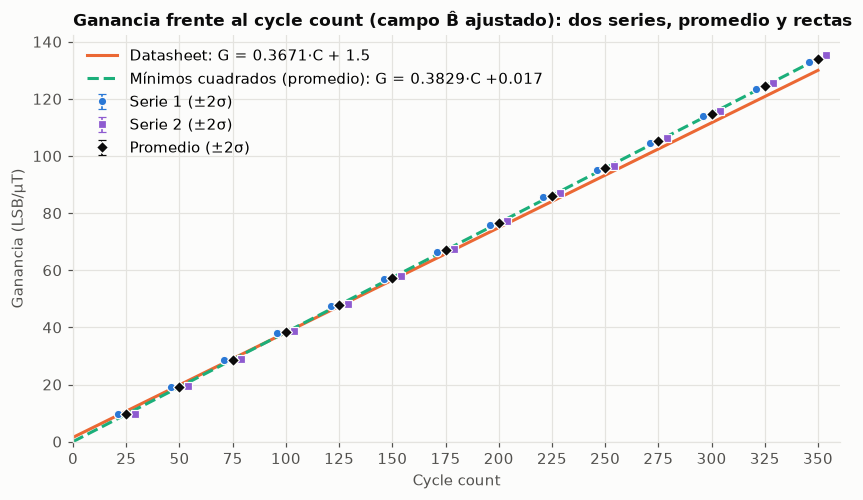

In [12]:
cc_recta = np.linspace(0, cc.max(), 300)
fp = RECTA_HAT["Promedio"]

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(cc_recta, DS_PENDIENTE * cc_recta + DS_OFFSET, color=C_DS, lw=2,
        label=f"Datasheet: G = {DS_PENDIENTE:.4f}·C + {DS_OFFSET:.1f}")
ax.plot(cc_recta, fp["a"] * cc_recta + fp["b"], color=C_FIT, lw=2, ls="--",
        label=f"Mínimos cuadrados (promedio): G = {fp['a']:.4f}·C {fp['b']:+.3f}")
for n, gs in GS_HAT.items():
    puntos(ax, cc, gs["G"], gs["U_G"], n, f"{n} (±2σ)")
ax.set_xlabel("Cycle count")
ax.set_ylabel("Ganancia (LSB/µT)")
ax.set_title("Ganancia frente al cycle count (campo B̂ ajustado): dos series, promedio y rectas")
ax.set_xticks(np.concatenate(([0], cc)))
ax.set_xlim(0, cc.max() * 1.03)
ax.set_ylim(0, None)
ax.legend(loc="upper left")
plt.show()

A la escala del gráfico anterior las tres series y las dos rectas se superponen. Para verlas separadas, el gráfico siguiente muestra lo mismo restando la recta del datasheet: el datasheet queda en cero y cada recta ajustada aparece como $\left(a-\alpha\right)C+\left(b-\beta\right)$.

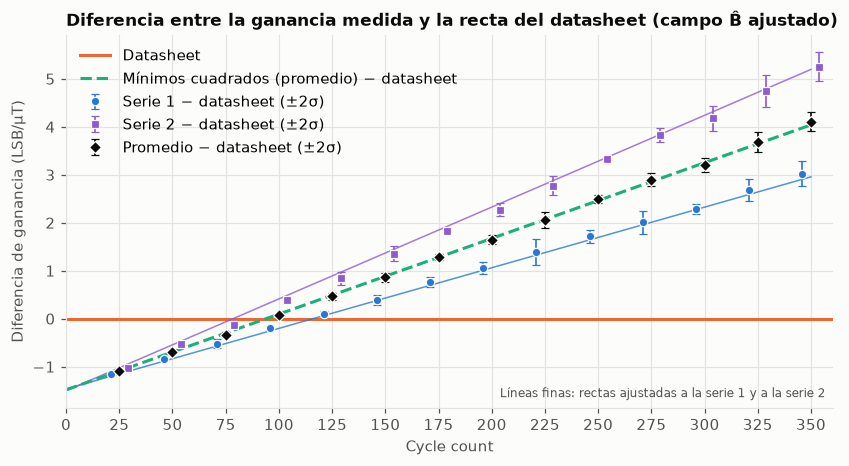

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.axhline(0, color=C_DS, lw=2, label="Datasheet")
for n in ("Serie 1", "Serie 2"):
    f = RECTA_HAT[n]
    ax.plot(cc_recta, (f["a"] - DS_PENDIENTE) * cc_recta + (f["b"] - DS_OFFSET),
            color=ESTILO[n]["color"], lw=1.0, alpha=0.8)
ax.plot(cc_recta, (fp["a"] - DS_PENDIENTE) * cc_recta + (fp["b"] - DS_OFFSET), color=C_FIT,
        lw=2, ls="--", label="Mínimos cuadrados (promedio) − datasheet")
for n, gs in GS_HAT.items():
    puntos(ax, cc, gs["G"] - G_ds, gs["U_G"], n, f"{n} − datasheet (±2σ)")
ax.set_xlabel("Cycle count")
ax.set_ylabel("Diferencia de ganancia (LSB/µT)")
ax.set_title("Diferencia entre la ganancia medida y la recta del datasheet (campo B̂ ajustado)")
ax.set_xticks(np.concatenate(([0], cc)))
ax.set_xlim(0, cc.max() * 1.03)
ax.legend(loc="upper left")
ax.text(0.99, 0.02, "Líneas finas: rectas ajustadas a la serie 1 y a la serie 2",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=8, color=TINTA2)
plt.show()

## 8. Campo del modelo IGRF-14

Hasta aquí el campo $\hat B$ se obtuvo de las propias cuentas, usando el modelo del datasheet. Una alternativa que **no** usa el datasheet es tomar el campo geomagnético que predice un modelo de referencia en el lugar y la fecha de la medición. Se usa la última generación del *International Geomagnetic Reference Field*, **IGRF-14** (IAGA, noviembre de 2024), válida hasta 2030,0. Los coeficientes se leen del archivo oficial `igrf14coeffs.txt` (NOAA/IAGA), copiado junto al notebook, y el modelo se evalúa aquí mismo, sin paquetes externos.

### 8.1 Potencial y componentes del campo

En la superficie terrestre, fuera de las fuentes del campo principal, no hay corrientes, de modo que $\nabla\times\mathbf B=\mathbf 0$ y el campo se puede escribir como gradiente de un potencial escalar, $\mathbf B=-\nabla V$. Como además $\nabla\cdot\mathbf B=0$, el potencial cumple la ecuación de Laplace, $\nabla^2V=0$. Su solución para fuentes interiores (la que decrece con la distancia) en coordenadas esféricas geocéntricas $(r,\theta,\phi)$ —radio, colatitud y longitud este— es el desarrollo en armónicos esféricos que define el IGRF:

$$
V(r,\theta,\phi,t)=a\sum_{n=1}^{N}\left(\frac{a}{r}\right)^{n+1}\sum_{m=0}^{n}\left[g_n^m(t)\cos m\phi+h_n^m(t)\sin m\phi\right]P_n^m(\cos\theta), \tag{28}
$$

con $a=6371{,}2$ km el radio de referencia, $N=13$ el grado máximo, $g_n^m$ y $h_n^m$ los coeficientes de Gauss (en nT) y $P_n^m$ las funciones asociadas de Legendre con la normalización de Schmidt (sección 8.2).

El gradiente en coordenadas esféricas es $\nabla V=\left(\partial_rV,\ \tfrac1r\partial_\theta V,\ \tfrac{1}{r\sin\theta}\partial_\phi V\right)$. Se abrevia $A_n^m\equiv g_n^m\cos m\phi+h_n^m\sin m\phi$ y se deriva (28) término a término.

*Componente radial* (derivada respecto de $r$ con $\theta$ y $\phi$ constantes). Solo depende de $r$ el factor $a\,(a/r)^{n+1}=a^{n+2}\,r^{-(n+1)}$:

$$
\frac{\partial}{\partial r}\left[a^{n+2}r^{-(n+1)}\right]=-(n+1)\,a^{n+2}\,r^{-(n+2)}=-(n+1)\left(\frac{a}{r}\right)^{n+2},
$$

por lo que

$$
B_r=-\left(\frac{\partial V}{\partial r}\right)_{\theta,\phi}=\sum_{n=1}^{N}(n+1)\left(\frac{a}{r}\right)^{n+2}\sum_{m=0}^{n}A_n^m\,P_n^m(\cos\theta). \tag{29}
$$

*Componente colatitudinal* (derivada respecto de $\theta$ con $r$ y $\phi$ constantes). Solo depende de $\theta$ la función $P_n^m(\cos\theta)$, y el factor $1/r$ del gradiente se combina con el prefactor: $\tfrac1r\,a\,(a/r)^{n+1}=(a/r)^{n+2}$. Entonces

$$
B_\theta=-\frac1r\left(\frac{\partial V}{\partial\theta}\right)_{r,\phi}=-\sum_{n=1}^{N}\left(\frac{a}{r}\right)^{n+2}\sum_{m=0}^{n}A_n^m\,\frac{dP_n^m(\cos\theta)}{d\theta}. \tag{30}
$$

*Componente azimutal* (derivada respecto de $\phi$ con $r$ y $\theta$ constantes). Solo depende de $\phi$ el factor $A_n^m$:

$$
\frac{\partial A_n^m}{\partial\phi}=-m\,g_n^m\sin m\phi+m\,h_n^m\cos m\phi=-m\left[g_n^m\sin m\phi-h_n^m\cos m\phi\right],
$$

y con el mismo factor $(a/r)^{n+2}$:

$$
B_\phi=-\frac{1}{r\sin\theta}\left(\frac{\partial V}{\partial\phi}\right)_{r,\theta}=\frac{1}{\sin\theta}\sum_{n=1}^{N}\left(\frac{a}{r}\right)^{n+2}\sum_{m=0}^{n}m\left[g_n^m\sin m\phi-h_n^m\cos m\phi\right]P_n^m(\cos\theta). \tag{31}
$$

*Módulo.* Lo que se compara con las cuentas es el módulo del campo (ecuación (2)):

$$
B_{\text{IGRF}}=\sqrt{B_r^2+B_\theta^2+B_\phi^2}. \tag{32}
$$

Las componentes (29)–(31) están referidas a la base geocéntrica, que difiere de la base local norte–este–vertical (geodésica) en una rotación de menos de $0{,}2^\circ$. El módulo de un vector no cambia con una rotación de la base, así que para (32) no hace falta aplicarla.

### 8.2 Funciones de Schmidt y sus derivadas

Los coeficientes del IGRF están definidos para las funciones asociadas de Legendre con normalización de Schmidt (seminormalizadas):

$$
P_n^m(x)=\sqrt{(2-\delta_{m0})\frac{(n-m)!}{(n+m)!}}\;\left(1-x^2\right)^{m/2}\frac{d^m}{dx^m}P_n(x),\qquad x=\cos\theta, \tag{33}
$$

donde $P_n$ es el polinomio de Legendre de grado $n$ y $\delta_{m0}$ vale 1 si $m=0$ y 0 en otro caso (sin el factor de fase $(-1)^m$ de Condon–Shortley). Se calculan con las recurrencias estándar de estas funciones, partiendo de $P_0^0=1$:

$$
\begin{aligned}
P_1^1&=\sin\theta\,P_0^0,\qquad P_n^n=\sqrt{\frac{2n-1}{2n}}\,\sin\theta\,P_{n-1}^{n-1}\quad(n\ge2),\\
P_n^m&=\frac{(2n-1)\cos\theta\,P_{n-1}^m-\sqrt{(n-1)^2-m^2}\,P_{n-2}^m}{\sqrt{n^2-m^2}}\quad(0\le m<n),
\end{aligned}
\tag{34}
$$

con $P_{n-2}^m\equiv0$ cuando $m>n-2$. Estas recurrencias se usan aquí como identidades conocidas, sin demostrarlas; por eso la celda de código **comprueba numéricamente** que reproducen la definición (33), evaluada de forma independiente con `scipy.special.lpmv`.

Para (30) hacen falta las derivadas respecto de $\theta$. Se obtienen derivando (34) con la regla del producto, usando $d(\sin\theta)/d\theta=\cos\theta$ y $d(\cos\theta)/d\theta=-\sin\theta$, y partiendo de $dP_0^0/d\theta=0$:

$$
\begin{aligned}
\frac{dP_n^n}{d\theta}&=\sqrt{\frac{2n-1}{2n}}\left[\cos\theta\,P_{n-1}^{n-1}+\sin\theta\,\frac{dP_{n-1}^{n-1}}{d\theta}\right]\quad(n\ge2;\ \text{para } n=1 \text{ el factor es } 1),\\
\frac{dP_n^m}{d\theta}&=\frac{(2n-1)\left[-\sin\theta\,P_{n-1}^m+\cos\theta\,\dfrac{dP_{n-1}^m}{d\theta}\right]-\sqrt{(n-1)^2-m^2}\,\dfrac{dP_{n-2}^m}{d\theta}}{\sqrt{n^2-m^2}}\quad(0\le m<n).
\end{aligned}
\tag{35}
$$

### 8.3 Dependencia temporal

Entre 2025,0 y 2030,0 el IGRF-14 da los coeficientes en la época $T_0=2025{,}0$ y su variación secular $\dot g_n^m,\dot h_n^m$ (nT/año), y prescribe una dependencia lineal:

$$
g_n^m(t)=g_n^m(T_0)+\dot g_n^m\,(t-T_0),\qquad h_n^m(t)=h_n^m(T_0)+\dot h_n^m\,(t-T_0),\qquad T_0\le t\le T_0+5, \tag{36}
$$

con $t$ en años decimales. Para la fecha de la medición (noviembre de 2026) es una **predicción** del modelo, no un valor definitivo.

### 8.4 De coordenadas geodésicas a geocéntricas

La latitud y la altura de un lugar se dan respecto del elipsoide (coordenadas geodésicas: latitud $\varphi$, altura $h$), mientras que (28) usa coordenadas geocéntricas. Para el elipsoide WGS84, de semieje mayor $a_e=6378{,}137$ km y achatamiento $f=1/298{,}257223563$, con excentricidad al cuadrado $e^2=f(2-f)$ y radio de curvatura del primer vertical $N_\varphi=a_e/\sqrt{1-e^2\sin^2\varphi}$, la distancia al eje de rotación y la altura sobre el plano ecuatorial del punto son (relaciones estándar del elipsoide de revolución, usadas aquí sin demostración)

$$
\rho=\left(N_\varphi+h\right)\cos\varphi,\qquad z=\left[N_\varphi\left(1-e^2\right)+h\right]\sin\varphi, \tag{37}
$$

y de ellas se obtienen el radio y la colatitud geocéntricos; la longitud es la misma en ambos sistemas:

$$
r=\sqrt{\rho^2+z^2},\qquad \theta=\operatorname{atan2}(\rho,z),\qquad \phi=\lambda. \tag{38}
$$

### 8.5 Qué representa y qué no representa este campo

El IGRF describe solo el **campo principal** de origen interno (núcleo) hasta grado 13. No contiene el campo cortical local, ni los campos externos (variación diurna y tormentas, típicamente decenas de nT), ni —lo más importante aquí— el campo que producen los **objetos cercanos al sensor**: estructuras de acero, muebles metálicos, imanes, fuentes de alimentación o el propio montaje. En el interior de un edificio estas perturbaciones pueden ser del orden del campo terrestre o mayores. Usar $B_{\text{IGRF}}$ en (15) equivale entonces a **suponer** que el campo en el sensor es el geomagnético no perturbado; con estos datos esa hipótesis no se puede dar por cierta, y la sección 10 la pone a prueba.

El lugar de la medición (`LAT_GEOD`, `LON`, `ALT_KM` en la primera celda) es también un supuesto que conviene corregir si no corresponde. Como referencia de su influencia, el campo del IGRF cambia del orden de unos pocos nT por km de desplazamiento horizontal.

In [14]:
A_REF = 6371.2                     # radio de referencia del IGRF (km)
N_MAX = 13                         # grado maximo del IGRF-14


def leer_igrf(ruta):
    """Lee igrf14coeffs.txt: epocas y coeficientes g[(n, m)], h[(n, m)] (ultima columna = SV)."""
    epocas, g, h = None, {}, {}
    with open(ruta, encoding="utf-8") as f:
        for linea in f:
            p = linea.split()
            if not p or p[0].startswith("#"):
                continue
            if p[0] == "g/h":
                epocas = np.array([float(x) for x in p[3:-1]])
            elif p[0] in ("g", "h"):
                (g if p[0] == "g" else h)[(int(p[1]), int(p[2]))] = np.array([float(x) for x in p[3:]])
    return epocas, g, h


def coeficientes(epocas, g, h, t):
    """Coeficientes en el instante t (anio decimal), ecuacion (36)."""
    T0 = epocas[-1]
    assert T0 <= t <= T0 + 5, "fecha fuera del intervalo de validez de la variacion secular"
    return ({k: v[-2] + v[-1] * (t - T0) for k, v in g.items()},
            {k: v[-2] + v[-1] * (t - T0) for k, v in h.items()})


def schmidt(theta, N=N_MAX):
    """Funciones de Schmidt P[n, m] y sus derivadas dP[n, m] respecto de theta, ecs. (34) y (35)."""
    c, s = math.cos(theta), math.sin(theta)
    P, dP = np.zeros((N + 1, N + 1)), np.zeros((N + 1, N + 1))
    P[0, 0] = 1.0
    for n in range(1, N + 1):
        k = 1.0 if n == 1 else math.sqrt((2 * n - 1) / (2 * n))
        P[n, n] = k * s * P[n - 1, n - 1]
        dP[n, n] = k * (c * P[n - 1, n - 1] + s * dP[n - 1, n - 1])
        for m in range(n):
            q = math.sqrt(n * n - m * m)
            k2 = math.sqrt((n - 1)**2 - m * m) if m <= n - 2 else 0.0
            P2, dP2 = (P[n - 2, m], dP[n - 2, m]) if m <= n - 2 else (0.0, 0.0)
            P[n, m] = ((2 * n - 1) * c * P[n - 1, m] - k2 * P2) / q
            dP[n, m] = ((2 * n - 1) * (-s * P[n - 1, m] + c * dP[n - 1, m]) - k2 * dP2) / q
    return P, dP


def potencial(r, theta, phi, gt, ht):
    """Potencial V (nT km), ecuacion (28)."""
    P, _ = schmidt(theta)
    return sum(A_REF * (A_REF / r)**(n + 1)
               * (gt[(n, m)] * math.cos(m * phi) + ht.get((n, m), 0.0) * math.sin(m * phi)) * P[n, m]
               for n in range(1, N_MAX + 1) for m in range(n + 1))


def campo_igrf(r, theta, phi, gt, ht):
    """Componentes geocentricas (B_r, B_theta, B_phi) en nT, ecuaciones (29) a (31)."""
    P, dP = schmidt(theta)
    Br = Bt = Bp = 0.0
    for n in range(1, N_MAX + 1):
        f = (A_REF / r)**(n + 2)
        for m in range(n + 1):
            gnm, hnm = gt[(n, m)], ht.get((n, m), 0.0)
            A = gnm * math.cos(m * phi) + hnm * math.sin(m * phi)
            Br += (n + 1) * f * A * P[n, m]                                                  # (29)
            Bt += -f * A * dP[n, m]                                                          # (30)
            Bp += f * m * (gnm * math.sin(m * phi) - hnm * math.cos(m * phi)) * P[n, m] / math.sin(theta)  # (31)
    return Br, Bt, Bp


def geodesicas_a_geocentricas(lat_grados, alt_km):
    """Radio (km) y colatitud (rad) geocentricos, ecuaciones (37) y (38), elipsoide WGS84."""
    a_e, fl = 6378.137, 1 / 298.257223563
    e2 = fl * (2 - fl)
    lat = math.radians(lat_grados)
    N_phi = a_e / math.sqrt(1 - e2 * math.sin(lat)**2)
    rho = (N_phi + alt_km) * math.cos(lat)
    z = (N_phi * (1 - e2) + alt_km) * math.sin(lat)
    return math.hypot(rho, z), math.atan2(rho, z)


def anio_decimal(fecha):
    ini = pd.Timestamp(year=fecha.year, month=1, day=1)
    fin = pd.Timestamp(year=fecha.year + 1, month=1, day=1)
    return fecha.year + (fecha - ini) / (fin - ini)


def B_igrf_uT(fecha, detalle=False):
    """Modulo del campo IGRF-14 (uT) en el lugar configurado, ecuacion (32)."""
    gt, ht = coeficientes(EPOCAS, G_IGRF, H_IGRF, anio_decimal(fecha))
    r, theta = geodesicas_a_geocentricas(LAT_GEOD, ALT_KM)
    Br, Bt, Bp = campo_igrf(r, theta, math.radians(LON), gt, ht)
    F = math.sqrt(Br**2 + Bt**2 + Bp**2) / 1000.0
    return (F, (Br, Bt, Bp), (r, theta)) if detalle else F


EPOCAS, G_IGRF, H_IGRF = leer_igrf(buscar(ARCHIVO_IGRF))
assert EPOCAS[-1] == 2025.0 and len(G_IGRF) == 104 and len(H_IGRF) == 91, "archivo IGRF inesperado"

fecha_med = pd.to_datetime(datos["pc_time"]).mean()         # instante medio del archivo
B_IGRF, (Br, Bt, Bp), (r_gc, th_gc) = B_igrf_uT(fecha_med, detalle=True)

print(f"Lugar supuesto: {LUGAR}  (lat {LAT_GEOD}°, lon {LON}°, alt {ALT_KM} km)")
print(f"Fecha: {fecha_med:%Y-%m-%d %H:%M}  ->  t = {anio_decimal(fecha_med):.4f}")
print(f"Geocéntricas: r = {r_gc:.3f} km, colatitud = {math.degrees(th_gc):.4f}°")
print(f"B_r = {Br:.1f} nT   B_theta = {Bt:.1f} nT   B_phi = {Bp:.1f} nT")
print(f"B_IGRF = {B_IGRF:.3f} µT")

Lugar supuesto: Santiago de Chile (campus USACH)  (lat -33.4489°, lon -70.6828°, alt 0.52 km)
Fecha: 2026-11-13 16:59  ->  t = 2026.8677
Geocéntricas: r = 6372.198 km, colatitud = 123.2722°
B_r = 13541.7 nT   B_theta = -18951.1 nT   B_phi = 47.7 nT
B_IGRF = 23.292 µT


**Comprobaciones de la implementación.** Antes de usar el valor se verifica: (a) que las recurrencias (34) reproducen la definición (33), evaluada de forma independiente con `scipy.special.lpmv` (que incluye la fase $(-1)^m$, que aquí se deshace); (b) que las derivadas (35) coinciden con una derivada numérica centrada de (34); y (c) que las componentes (29)–(31) coinciden con el gradiente numérico del potencial (28). Las tres pruebas validan el álgebra y la normalización; no validan el archivo de coeficientes ni el lugar supuesto.

In [15]:
from scipy.special import lpmv

gt, ht = coeficientes(EPOCAS, G_IGRF, H_IGRF, anio_decimal(fecha_med))
phi_gc = math.radians(LON)

# (a) recurrencias (34) frente a la definicion (33)
P, dP = schmidt(th_gc)
err_P = max(abs(P[n, m] - (-1)**m * math.sqrt((2 - (m == 0)) * math.factorial(n - m) / math.factorial(n + m))
                * lpmv(m, n, math.cos(th_gc)))
            for n in range(N_MAX + 1) for m in range(n + 1))

# (b) derivadas (35) frente a la derivada numerica centrada de (34)
eps = 1e-6
err_dP = np.abs((schmidt(th_gc + eps)[0] - schmidt(th_gc - eps)[0]) / (2 * eps) - dP).max()

# (c) componentes (29)-(31) frente al gradiente numerico del potencial (28)
dr = 1e-3
Br_num = -(potencial(r_gc + dr, th_gc, phi_gc, gt, ht) - potencial(r_gc - dr, th_gc, phi_gc, gt, ht)) / (2 * dr)
Bt_num = -(potencial(r_gc, th_gc + eps, phi_gc, gt, ht) - potencial(r_gc, th_gc - eps, phi_gc, gt, ht)) / (2 * eps) / r_gc
Bp_num = -(potencial(r_gc, th_gc, phi_gc + eps, gt, ht) - potencial(r_gc, th_gc, phi_gc - eps, gt, ht)) / (2 * eps) / (r_gc * math.sin(th_gc))
err_B = max(abs(Br - Br_num), abs(Bt - Bt_num), abs(Bp - Bp_num))

print(f"(a) max |P - definicion|        = {err_P:.1e}")
print(f"(b) max |dP - derivada numerica| = {err_dP:.1e}")
print(f"(c) max |B - gradiente numerico| = {err_B:.1e} nT")
assert err_P < 1e-12 and err_dP < 1e-7 and err_B < 1e-3

(a) max |P - definicion|        = 3.3e-16
(b) max |dP - derivada numerica| = 3.7e-10
(c) max |B - gradiente numerico| = 1.4e-05 nT


## 9. Comparación del campo usado: $\hat B$ ajustado frente a $B_{\text{IGRF}}$

**Dos elecciones de escala.** La ganancia (15) necesita un valor de campo. Se comparan dos:

- $\hat B$ de (17): es el campo que hace que la recta del datasheet pase lo mejor posible por los datos. **Depende del datasheet** y, por construcción, deja las ganancias cerca de él.
- $B_{\text{IGRF}}$ de (32): **no depende del datasheet ni de los datos**, pero supone que el campo en el sensor es el geomagnético no perturbado (sección 8.5), y es el mismo para las dos series y el promedio.

**Relación entre los dos resultados.** Para una misma serie, las dos ganancias se obtienen del mismo $\bar M_i$:

$$
G_i^{\text{IGRF}}=\frac{\bar M_i}{B_{\text{IGRF}}}=\frac{\bar M_i}{\hat B}\cdot\frac{\hat B}{B_{\text{IGRF}}}=f\,G_i^{\hat B},\qquad f\equiv\frac{\hat B}{B_{\text{IGRF}}}. \tag{39}
$$

El cambio de campo es un cambio de escala común a todos los *cycle counts*. La incertidumbre tipo A escala igual, $u\!\left(G_i^{\text{IGRF}}\right)=u\!\left(\bar M_i\right)/B_{\text{IGRF}}=f\,u\!\left(G_i^{\hat B}\right)$, y la sensibilidad (20) con el inverso:

$$
S_i^{\text{IGRF}}=\frac{1000}{G_i^{\text{IGRF}}}=\frac{1000}{f\,G_i^{\hat B}}=\frac{S_i^{\hat B}}{f},\qquad U\!\left(S_i^{\text{IGRF}}\right)=S_i^{\text{IGRF}}\frac{U_i}{\bar M_i}=\frac{U\!\left(S_i^{\hat B}\right)}{f}, \tag{40}
$$

donde se usó (21): la incertidumbre relativa de $S_i$ es $U_i/\bar M_i$, que no depende del campo elegido.

**Efecto sobre la recta de mínimos cuadrados.** Con $G_i\to f\,G_i$ y $u(G_i)\to f\,u(G_i)$, los pesos de (24) pasan a $w_i\to w_i/f^2$ y las sumas de (25) a

$$
S_w\to\frac{S_w}{f^2},\qquad S_x\to\frac{S_x}{f^2},\qquad S_{xx}\to\frac{S_{xx}}{f^2},\qquad
S_y=\sum_i w_iG_i\to\sum_i\frac{w_i}{f^2}\,f\,G_i=\frac{S_y}{f},\qquad S_{xy}\to\frac{S_{xy}}{f},
$$

de modo que $\Delta=S_wS_{xx}-S_x^2\to\Delta/f^4$. Sustituyendo en (26):

$$
\begin{aligned}
a^{\text{IGRF}}&=\frac{\dfrac{S_w}{f^2}\dfrac{S_{xy}}{f}-\dfrac{S_x}{f^2}\dfrac{S_y}{f}}{\dfrac{\Delta}{f^4}}
=\frac{f^4}{f^3}\cdot\frac{S_wS_{xy}-S_xS_y}{\Delta}=f\,a^{\hat B},\\
b^{\text{IGRF}}&=\frac{\dfrac{S_{xx}}{f^2}\dfrac{S_y}{f}-\dfrac{S_x}{f^2}\dfrac{S_{xy}}{f}}{\dfrac{\Delta}{f^4}}
=\frac{f^4}{f^3}\cdot\frac{S_{xx}S_y-S_xS_{xy}}{\Delta}=f\,b^{\hat B},
\end{aligned}
\tag{41}
$$

y en (27):

$$
u\!\left(a^{\text{IGRF}}\right)=\sqrt{\frac{S_w/f^2}{\Delta/f^4}}=f\sqrt{\frac{S_w}{\Delta}}=f\,u\!\left(a^{\hat B}\right),\qquad
u\!\left(b^{\text{IGRF}}\right)=\sqrt{\frac{S_{xx}/f^2}{\Delta/f^4}}=f\,u\!\left(b^{\hat B}\right). \tag{42}
$$

**Qué cambia y qué no.** De (41) y (42):

- la pendiente, la ordenada y sus incertidumbres se multiplican por $f$;
- el cociente $b/a$, la significación de $b$ frente a cero, $b/u(b)$, y el $\chi^2$ del ajuste, $\sum_i w_i(G_i-aC_i-b)^2\to\sum_i\frac{w_i}{f^2}f^2(G_i-aC_i-b)^2$, **no cambian**;
- la comparación con las constantes del datasheet ($a$ frente a $\alpha$, $b$ frente a $\beta=1{,}5$, y las desviaciones de la sensibilidad) **sí cambia**, porque $\alpha$ y $\beta$ no se reescalan.

Es decir: elegir el campo decide la **escala absoluta** de la ganancia, y no afecta a la conclusión sobre la **forma** de su dependencia con el *cycle count*.

In [16]:
GS_IGRF = {n: ganancia_sensibilidad(M, u, B_IGRF) for n, (M, u) in SERIES.items()}
RECTA_IGRF = {n: ajustar_recta(gs["G"], gs["u_G"]) for n, gs in GS_IGRF.items()}

# Comprobacion numerica de (39), (41) y (42)
for n in SERIES:
    f_esc = B_HAT[n] / B_IGRF
    assert np.allclose(GS_IGRF[n]["G"], f_esc * GS_HAT[n]["G"])
    for clave in ("a", "b", "U_a", "U_b"):
        assert np.isclose(RECTA_IGRF[n][clave], f_esc * RECTA_HAT[n][clave])
    assert np.isclose(RECTA_IGRF[n]["chi2/nu ajuste"], RECTA_HAT[n]["chi2/nu ajuste"])

i200 = int(np.where(cc == 200)[0][0])
filas = {}
for campo, B_de, GS, RECTA in (("B̂ ajustado", B_HAT, GS_HAT, RECTA_HAT),
                               ("IGRF-14", {n: B_IGRF for n in SERIES}, GS_IGRF, RECTA_IGRF)):
    for n in SERIES:
        f = RECTA[n]
        filas[(campo, n)] = {"B (µT)": B_de[n], "f = B̂/B": B_HAT[n] / B_de[n],
                             "a": f["a"], "U_a": f["U_a"], "b": f["b"], "U_b": f["U_b"],
                             "a/alfa": f["a"] / DS_PENDIENTE, "b/a": f["b"] / f["a"],
                             "chi2/nu ajuste": f["chi2/nu ajuste"],
                             "G(200)": GS[n]["G"][i200], "S(200)": GS[n]["S"][i200]}
comp = pd.DataFrame(filas).T
print(f"Datasheet: a = {DS_PENDIENTE}, b = {DS_OFFSET}, G(200) = {G_ds[i200]:.2f} LSB/µT, S(200) = {S_ds[i200]:.2f} nT/LSB")
comp.style.format({"B (µT)": "{:.2f}", "f = B̂/B": "{:.3f}", "a": "{:.4f}", "U_a": "{:.4f}",
                   "b": "{:+.3f}", "U_b": "{:.3f}", "a/alfa": "{:.3f}", "b/a": "{:+.2f}",
                   "chi2/nu ajuste": "{:.2f}", "G(200)": "{:.2f}", "S(200)": "{:.2f}"})

Datasheet: a = 0.3671, b = 1.5, G(200) = 74.92 LSB/µT, S(200) = 13.35 nT/LSB


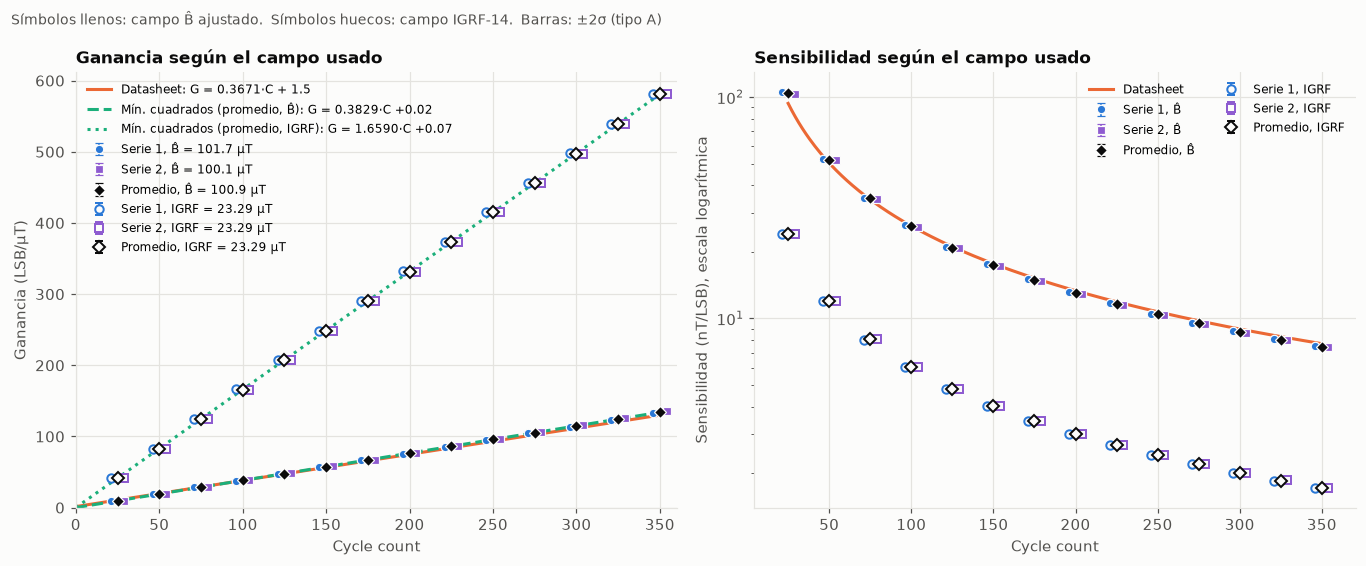

In [17]:
fig, (axg, axs) = plt.subplots(1, 2, figsize=(12.5, 5.2))

# ---- Ganancia ----
axg.plot(cc_recta, DS_PENDIENTE * cc_recta + DS_OFFSET, color=C_DS, lw=2,
         label=f"Datasheet: G = {DS_PENDIENTE:.4f}·C + {DS_OFFSET:.1f}")
for RECTA, estilo, nombre in ((RECTA_HAT, "--", "B̂"), (RECTA_IGRF, ":", "IGRF")):
    f = RECTA["Promedio"]
    axg.plot(cc_recta, f["a"] * cc_recta + f["b"], color=C_FIT, lw=2, ls=estilo,
             label=f"Mín. cuadrados (promedio, {nombre}): G = {f['a']:.4f}·C {f['b']:+.2f}")
for n in SERIES:
    puntos(axg, cc, GS_HAT[n]["G"], GS_HAT[n]["U_G"], n, f"{n}, B̂ = {B_HAT[n]:.1f} µT")
for n in SERIES:
    puntos(axg, cc, GS_IGRF[n]["G"], GS_IGRF[n]["U_G"], n, f"{n}, IGRF = {B_IGRF:.2f} µT", hueco=True)
axg.set_xlabel("Cycle count")
axg.set_ylabel("Ganancia (LSB/µT)")
axg.set_title("Ganancia según el campo usado")
axg.set_xticks(np.concatenate(([0], cc[1::2])))
axg.set_xlim(0, cc.max() * 1.03)
axg.set_ylim(0, None)
axg.legend(loc="upper left", fontsize=8)

# ---- Sensibilidad (escala logaritmica: los dos resultados difieren en un factor constante) ----
axs.plot(cc_fino, 1000.0 / (DS_PENDIENTE * cc_fino + DS_OFFSET), color=C_DS, lw=2, label="Datasheet")
for n in SERIES:
    puntos(axs, cc, GS_HAT[n]["S"], GS_HAT[n]["U_S"], n, f"{n}, B̂")
for n in SERIES:
    puntos(axs, cc, GS_IGRF[n]["S"], GS_IGRF[n]["U_S"], n, f"{n}, IGRF", hueco=True)
axs.set_yscale("log")
axs.set_xlabel("Cycle count")
axs.set_ylabel("Sensibilidad (nT/LSB), escala logarítmica")
axs.set_title("Sensibilidad según el campo usado")
axs.set_xticks(cc[1::2])
axs.legend(loc="upper right", fontsize=8, ncol=2)

fig.suptitle("Símbolos llenos: campo B̂ ajustado.  Símbolos huecos: campo IGRF-14.  Barras: ±2σ (tipo A)",
             fontsize=9, color=TINTA2, x=0.01, ha="left")
fig.tight_layout()
plt.show()

El gráfico anterior muestra la escala absoluta. Para ver a la vez la escala y la forma, el siguiente representa el cociente entre la ganancia medida y la del datasheet, $G_i/G_{\text{ds}}(C_i)$: el datasheet es la recta horizontal en 1. Por (39), los puntos calculados con el IGRF son los calculados con $\hat B$ multiplicados por $f$.

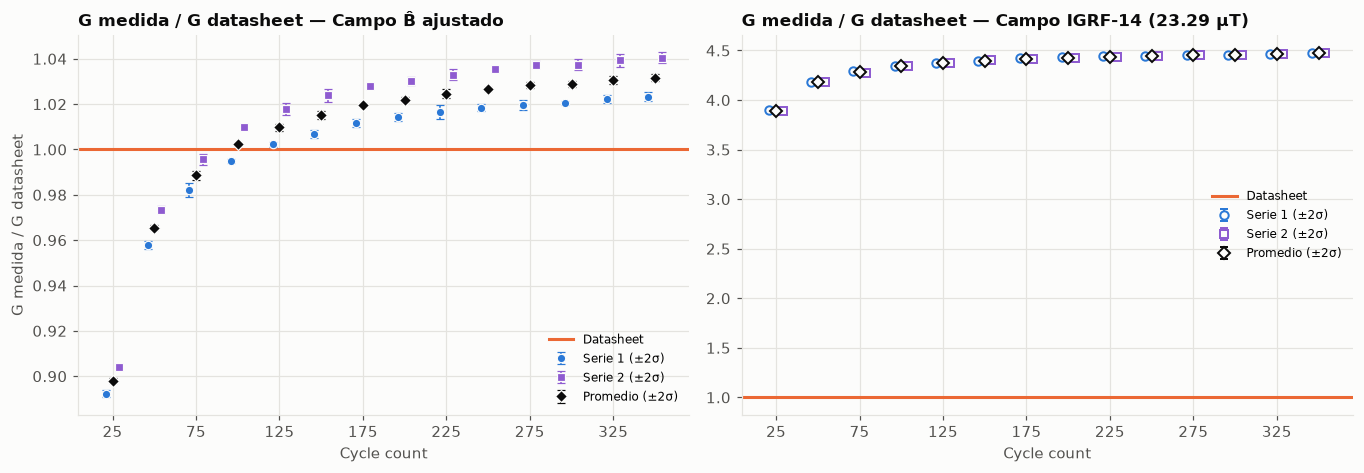

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.4), sharex=True)
for ax, GS, hueco, titulo in ((ax1, GS_HAT, False, "Campo B̂ ajustado"),
                              (ax2, GS_IGRF, True, f"Campo IGRF-14 ({B_IGRF:.2f} µT)")):
    ax.axhline(1, color=C_DS, lw=2, label="Datasheet")
    for n in SERIES:
        puntos(ax, cc, GS[n]["G"] / G_ds, GS[n]["U_G"] / G_ds, n, f"{n} (±2σ)", hueco=hueco)
    ax.set_xlabel("Cycle count")
    ax.set_title(f"G medida / G datasheet — {titulo}")
    ax.set_xticks(cc[::2])
    ax.legend(loc="center right" if hueco else "lower right", fontsize=8)
ax1.set_ylabel("G medida / G datasheet")
fig.tight_layout()
plt.show()

## 10. Comparación con el archivo del 12 de noviembre: una prueba del campo que no usa el datasheet

**Cantidad comparada.** El modelo proporcional (18) da, para cada archivo y serie, $\hat\kappa=\bar M/C$ en LSB por cuenta de ciclo. Por (2), $\bar M_i=G_iB$, de modo que si la ganancia por cuenta de ciclo del sensor, $\gamma\equiv G_i/C_i$, es una propiedad del sensor y del firmware (los mismos los dos días), entonces

$$
\hat\kappa=\frac{\bar M_i}{C_i}=\frac{G_i\,B}{C_i}=\gamma\,B. \tag{43}
$$

El cociente entre los valores de dos días distintos elimina $\gamma$ y da directamente el cociente de los campos **en el sensor**, sin usar el datasheet ni ningún modelo:

$$
\frac{\hat\kappa_{13}}{\hat\kappa_{12}}=\frac{\gamma\,B_{13}}{\gamma\,B_{12}}=\frac{B_{13}}{B_{12}}. \tag{44}
$$

**Predicción del IGRF.** Si el campo en el sensor fuera el geomagnético no perturbado, (44) debería valer $B_{\text{IGRF}}(13\text{-nov})/B_{\text{IGRF}}(12\text{-nov})$, que es prácticamente 1: en un día la variación secular (36) cambia el campo en una fracción de nT, y la variación diurna (no incluida en el IGRF) es de decenas de nT, es decir, del orden de $0{,}1\,\%$.

**Supuestos de (44).** Mismo sensor, mismo firmware y misma configuración de *cycle count* los dos días; la orientación del sensor no importa porque se usa el módulo.

In [19]:
ruta_ant = buscar(ARCHIVO_ANTERIOR)
if ruta_ant is None:
    print("No se encontró", ARCHIVO_ANTERIOR, "- se omite la comparación.")
else:
    ant = pd.read_csv(ruta_ant, sep="\t")
    ant["M_LSB"] = np.sqrt(ant["X_LSB"].astype(float)**2 + ant["Y_LSB"].astype(float)**2
                           + ant["Z_LSB"].astype(float)**2)
    ant = ant[ant["barrido"] == ant["barrido"].min()]
    res_ant = estadistica(ant)
    assert res_ant.index.equals(r1_.index)
    M_ant, u_ant = res_ant["M_media"].to_numpy(), res_ant["u_A_corr"].to_numpy()
    fecha_ant = pd.to_datetime(ant["pc_time"]).mean()
    B_IGRF_ant = B_igrf_uT(fecha_ant)

    filas = {}
    for etiqueta, M, u, B_i in ((f"12-nov, serie 1", M_ant, u_ant, B_IGRF_ant),
                                ("13-nov, serie 1", M1, u1, B_IGRF),
                                ("13-nov, serie 2", M2, u2, B_IGRF),
                                ("13-nov, promedio", Mp, up, B_IGRF)):
        aj = ajustar_campo(M, u)
        rec = ajustar_recta(M / aj["B_hat (uT)"], u / aj["B_hat (uT)"])
        filas[etiqueta] = {"kappa (LSB/cuenta)": aj["kappa (LSB/cuenta)"], "B_hat (µT)": aj["B_hat (uT)"],
                           "B_IGRF (µT)": B_i, "B_hat/B_IGRF": aj["B_hat (uT)"] / B_i,
                           "a (con B̂)": rec["a"], "b (con B̂)": rec["b"], "U_b": rec["U_b"],
                           "kappa/B_IGRF": aj["kappa (LSB/cuenta)"] / B_i}
    dias = pd.DataFrame(filas).T
    k12, k13 = dias.loc["12-nov, serie 1", "kappa (LSB/cuenta)"], dias.loc["13-nov, promedio", "kappa (LSB/cuenta)"]
    print(f"Cociente medido   kappa(13-nov, promedio) / kappa(12-nov) = {k13 / k12:.4f}     [ecuación (44)]")
    print(f"Cociente IGRF     B_IGRF(13-nov) / B_IGRF(12-nov)         = {B_IGRF / B_IGRF_ant:.6f}")
    print(f"Diferencia de B_IGRF entre los dos días: {1000 * (B_IGRF - B_IGRF_ant):+.2f} nT")
    display(dias.style.format({"kappa (LSB/cuenta)": "{:.3f}", "B_hat (µT)": "{:.2f}", "B_IGRF (µT)": "{:.3f}",
                               "B_hat/B_IGRF": "{:.2f}", "a (con B̂)": "{:.5f}", "b (con B̂)": "{:+.3f}",
                               "U_b": "{:.3f}", "kappa/B_IGRF": "{:.3f}"}))

Cociente medido   kappa(13-nov, promedio) / kappa(12-nov) = 1.6950     [ecuación (44)]
Cociente IGRF     B_IGRF(13-nov) / B_IGRF(12-nov)         = 0.999994
Diferencia de B_IGRF entre los dos días: -0.14 nT


,kappa (LSB/cuenta),B_hat (µT),B_IGRF (µT),B_hat/B_IGRF,a (con B̂),b (con B̂),U_b,kappa/B_IGRF
"12-nov, serie 1",22.808,60.15,23.292,2.58,0.37914,+0.005,0.020,0.979
"13-nov, serie 1",38.667,101.75,23.292,4.37,0.37974,+0.034,0.019,1.660
"13-nov, serie 2",38.649,100.07,23.292,4.30,0.38624,-0.001,0.011,1.659
"13-nov, promedio",38.660,100.92,23.292,4.33,0.38288,+0.017,0.011,1.660


## 11. Conclusiones para este archivo de datos

Los valores citados corresponden a `datos_raw_rm3100_20261113_163608.txt` y al lugar supuesto en la primera celda; si se cambia alguno hay que releer las tablas. Todas las incertidumbres son de tipo A, a $2\sigma$.

**1. Las dos series son compatibles entre sí (sección 4).** La diferencia $|d_i|$ es menor que $2\,u(d_i)$ en 13 de los 14 *cycle counts*, y en promedio la serie 1 queda un $0{,}08\,\%$ por encima de la serie 2. La excepción es *cycle count* 25, donde la serie 1 es un $0{,}34\,\%$ mayor ($3{,}3\,u(d)$).

**2. La ganancia sigue siendo proporcional al *cycle count* (secciones 6 y 7).** El modelo proporcional $\bar M=\kappa C$ da $\chi^2/\nu=1{,}15$, $0{,}74$ y $1{,}10$ (serie 1, serie 2, promedio), con $\hat\kappa=38{,}667$, $38{,}649$ y $38{,}660$ LSB por cuenta de ciclo. El modelo del datasheet, con el campo libre, da $\chi^2/\nu\approx1900$, $6100$ y $5200$. La ordenada en el origen de la recta ajustada es

$$
b=+0{,}034\pm0{,}019,\qquad -0{,}001\pm0{,}011,\qquad +0{,}017\pm0{,}011\ \ \text{LSB/µT}
$$

(serie 1, serie 2, promedio), frente a $\beta=1{,}5$ LSB/µT del datasheet. En la serie 1 y en el promedio $b$ no es estrictamente compatible con cero a $2\sigma$ (lo empuja el punto de *cycle count* 25 de la serie 1, el mismo que discrepa en la conclusión 1), pero es unas 90 veces menor que $\beta$: $b/a\le0{,}09$ cuentas de ciclo frente a $4{,}09$. Esta conclusión **no depende del campo usado** (ecuaciones (41) y (42)) y reproduce la del 12 de noviembre ($b=+0{,}005\pm0{,}020$).

**3. Ganancia y sensibilidad con $\hat B$ (promedio de las dos series).** Con $\hat B^{(p)}=100{,}92$ µT, la ganancia va de $9{,}59$ LSB/µT (*cycle count* 25) a $134{,}09$ LSB/µT (*cycle count* 350), frente a $10{,}68$ y $129{,}99$ del datasheet; la sensibilidad va de $104{,}3$ a $7{,}46$ nT/LSB, con una desviación respecto del datasheet de $+11{,}4\,\%$ en *cycle count* 25 que pasa por cero cerca de *cycle count* 100 y llega a $-3{,}1\,\%$ en 350. En los tres valores que tabula el datasheet (50, 26 y 13 nT para *cycle count* 50, 100 y 200) se obtiene $52{,}2$, $26{,}1$ y $13{,}1$ nT/LSB. La recta ajustada es

$$
G=(0{,}38288\pm0{,}00017)\,C+(0{,}017\pm0{,}011)\ \text{LSB/µT},\qquad \chi^2/\nu=0{,}45 .
$$

**4. $\hat B$ no es una escala reproducible (sección 6.1).** Las dos series difieren en $0{,}05\,\%$ en $\hat\kappa$, pero en $1{,}68\,\%$ en $\hat B$ ($101{,}75$ frente a $100{,}07$ µT). Esa diferencia se traslada íntegra a la ganancia: las pendientes ajustadas son $0{,}37974$ y $0{,}38624$, y en los gráficos de la sección 7 las dos series aparecen separadas unas 35 veces más de lo que difieren sus datos. La causa es (17a)–(17b): $\hat B$ promedia campos $B_i$ que van de $90{,}6$ a $104{,}1$ µT según el *cycle count*, con pesos que cambian de una serie a otra (por ejemplo, *cycle count* 25 pesa $6\,\%$ en la serie 1 y $21\,\%$ en la serie 2). Es un artefacto de ajustar un modelo —el del datasheet— que no describe los datos, no una diferencia física entre las series.

**5. Con el campo del IGRF-14 la escala cambia en un factor 4,3 (sección 9).** $B_{\text{IGRF}}=23{,}29$ µT, de modo que $f=\hat B/B_{\text{IGRF}}=4{,}37$, $4{,}30$ y $4{,}33$. Con este campo:

- las dos series coinciden, como sus datos: $a=1{,}6588$ y $1{,}6593$ LSB/µT por cuenta de ciclo ($0{,}03\,\%$ de diferencia), porque el mismo campo se aplica a ambas;
- la recta del promedio es $G=(1{,}6590\pm0{,}0007)\,C+(0{,}07\pm0{,}05)$ LSB/µT, con una pendiente $4{,}52$ veces la del datasheet;
- en *cycle count* 200 resultan $331{,}8$ LSB/µT y $3{,}01$ nT/LSB, frente a $74{,}9$ LSB/µT y $13{,}3$ nT/LSB del datasheet.

Una ganancia 4,5 veces mayor que la nominal no es creíble como propiedad del sensor; indica que el campo en el sensor no es el del IGRF.

**6. El campo en el sensor no es el geomagnético no perturbado (sección 10).** Sin usar el datasheet: el cociente (44) entre el 13 y el 12 de noviembre vale $1{,}695$, mientras que el IGRF cambia en $-0{,}14$ nT entre los dos días (cociente $0{,}999994$). El campo en el sensor aumentó un $70\,\%$ de un día a otro, algo que el campo terrestre no hace; equivalentemente, la "ganancia por cuenta de ciclo" calculada con el IGRF, $\hat\kappa/B_{\text{IGRF}}$, sería $0{,}98$ el día 12 y $1{,}66$ el día 13 para el mismo sensor. Además, con la pendiente del datasheet los campos implícitos son $\hat\kappa/\alpha\approx62$ µT y $\approx105$ µT, ambos muy por encima de los $23{,}3$ µT del IGRF en Santiago, y el segundo por encima del máximo del campo geomagnético en la superficie terrestre (unos 65 µT). El sensor está midiendo, sobre todo, el campo de objetos cercanos (sección 8.5), que cambió entre las dos sesiones.

**7. Respuesta a la pregunta de qué campo usar.** Ninguno de los dos sirve, con estos datos, para fijar la escala absoluta de la ganancia:

- $\hat B$ está construido a partir del datasheet (no puede validarlo en escala) y, además, depende de los pesos (conclusión 4);
- $B_{\text{IGRF}}$ es independiente del datasheet, pero no es el campo que ve el sensor (conclusiones 5 y 6).

Lo que sí queda establecido, con cualquiera de los dos campos y en los dos días, es la **forma**: ganancia proporcional al *cycle count*, sin el término constante $\beta=1{,}5$ LSB/µT. Para validar la escala hace falta un campo conocido en el sensor: una bobina de Helmholtz calibrada, un magnetómetro de referencia junto al RM3100, o repetir la medición al aire libre, lejos de estructuras y objetos metálicos, donde el IGRF sí es una buena aproximación (típicamente dentro de unos cientos de nT, del orden del $1\,\%$).

### Limitaciones

- **Lugar de la medición.** Latitud, longitud y altura son un supuesto (primera celda). No altera las conclusiones 5 y 6: ningún lugar de la Tierra tiene un campo geomagnético de 100 µT.
- **Implementación del IGRF.** Se comprobaron el álgebra y la normalización (sección 8), no el resultado contra una calculadora externa. Las recurrencias (34) y las relaciones (37) se usaron como identidades conocidas, sin demostrarlas.
- **Constantes del datasheet.** $\alpha$ y $\beta$ se transcribieron del código original; conviene verificarlas contra el documento del fabricante.
- **Solo incertidumbre tipo A**, con la corrección por correlación de la sección 2.1, que es una estimación de orden de magnitud. No se propaga la incertidumbre de $\hat B$ ni la de $B_{\text{IGRF}}$.
- **Independencia entre series** (8b) y **campo constante durante cada serie**: son hipótesis. Las apoya que $\bar M/C$ no muestre tendencia y que las series coincidan dentro de $0{,}1\,\%$ salvo en *cycle count* 25.
- **Comparación entre días** (44): supone el mismo sensor, firmware y configuración los dos días.
- **Ejes.** Se supuso la misma ganancia en los tres ejes.